# Transaction analysis

The initial distributions and null counts below inspect `tables/curated/transactions`: its fraud columns preserve supplied scores and original missingness. The UMAP also uses those original availability flags. Consumer spending history uses earlier dates.

For the completed analytical dataset, read `tables/analysis/transactions_imputed/transactions_imputed.parquet` (or its CSV counterpart). Its conventional fraud-score columns contain supplied-or-imputed scores, missing spending histories are filled, and provenance flags identify the estimates. Model diagnostics and figure files are kept internally under `tables/analysis/fraud_diagnostics/`.


In [1]:
from pathlib import Path
from pyspark.sql import SparkSession, functions as F

# Initialise this notebook before reading the curated tables.
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "tables/curated/transactions").is_dir()), None)
if root is None:
    raise FileNotFoundError("Run from the repository or code/ directory after completing 01_etl.ipynb.")
spark = SparkSession.builder.master("local[4]").appName("BNPL Analysis").getOrCreate()

transactions_df = spark.read.parquet(str(root / "tables/curated/transactions"))
null_counts_df = transactions_df.select([
    F.sum(F.col(column).isNull().cast("long")).alias(column)
    for column in transactions_df.columns
])
null_counts_df.show(truncate=False)

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/09/18 02:12:42 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+-------+--------------+--------+------------+------------+--------------------------+--------------------------+-----------------+---------------+------------------------+--------------+-----------------------+-----------------------+---------------------+-------------+----------------------+-----------+
|user_id|order_datetime|order_id|dollar_value|merchant_abn|consumer_fraud_probability|merchant_fraud_probability|consumer_postcode|consumer_gender|consumer_district_income|income_matched|consumer_record_matched|merchant_record_matched|consumer_avg_spending|spending_diff|absolute_spending_diff|order_month|
+-------+--------------+--------+------------+------------+--------------------------+--------------------------+-----------------+---------------+------------------------+--------------+-----------------------+-----------------------+---------------------+-------------+----------------------+-----------+
|0      |0             |0       |0           |0           |14115157            

In [2]:
from pathlib import Path
from zipfile import ZipFile
import requests

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tables/landing").is_dir())
boundary_dir = root / "tables/landing/abs_2021/postal_areas_2021"
boundary_dir.mkdir(parents=True, exist_ok=True)
boundary_zip = boundary_dir / "POA_2021_AUST_GDA2020_SHP.zip"
boundary_url = ("https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/"
                "edition-3-july-2021-june-2026/access-and-downloads/digital-boundary-files/"
                "POA_2021_AUST_GDA2020_SHP.zip")

if not next(boundary_dir.rglob("*.shp"), None):
    with requests.get(boundary_url, stream=True, timeout=180) as response:
        response.raise_for_status()
        with boundary_zip.open("wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)
    with ZipFile(boundary_zip) as archive:
        archive.extractall(boundary_dir)

postal_areas_shapefile = next(boundary_dir.rglob("*.shp"))
print(f"Postal Areas shapefile ready: {postal_areas_shapefile}")

Postal Areas shapefile ready: /Users/trollinmaster/Documents/Uni/Coding/VSCode/MAST30034/industry-project-group-19/tables/landing/abs_2021/postal_areas_2021/POA_2021_AUST_GDA2020.shp


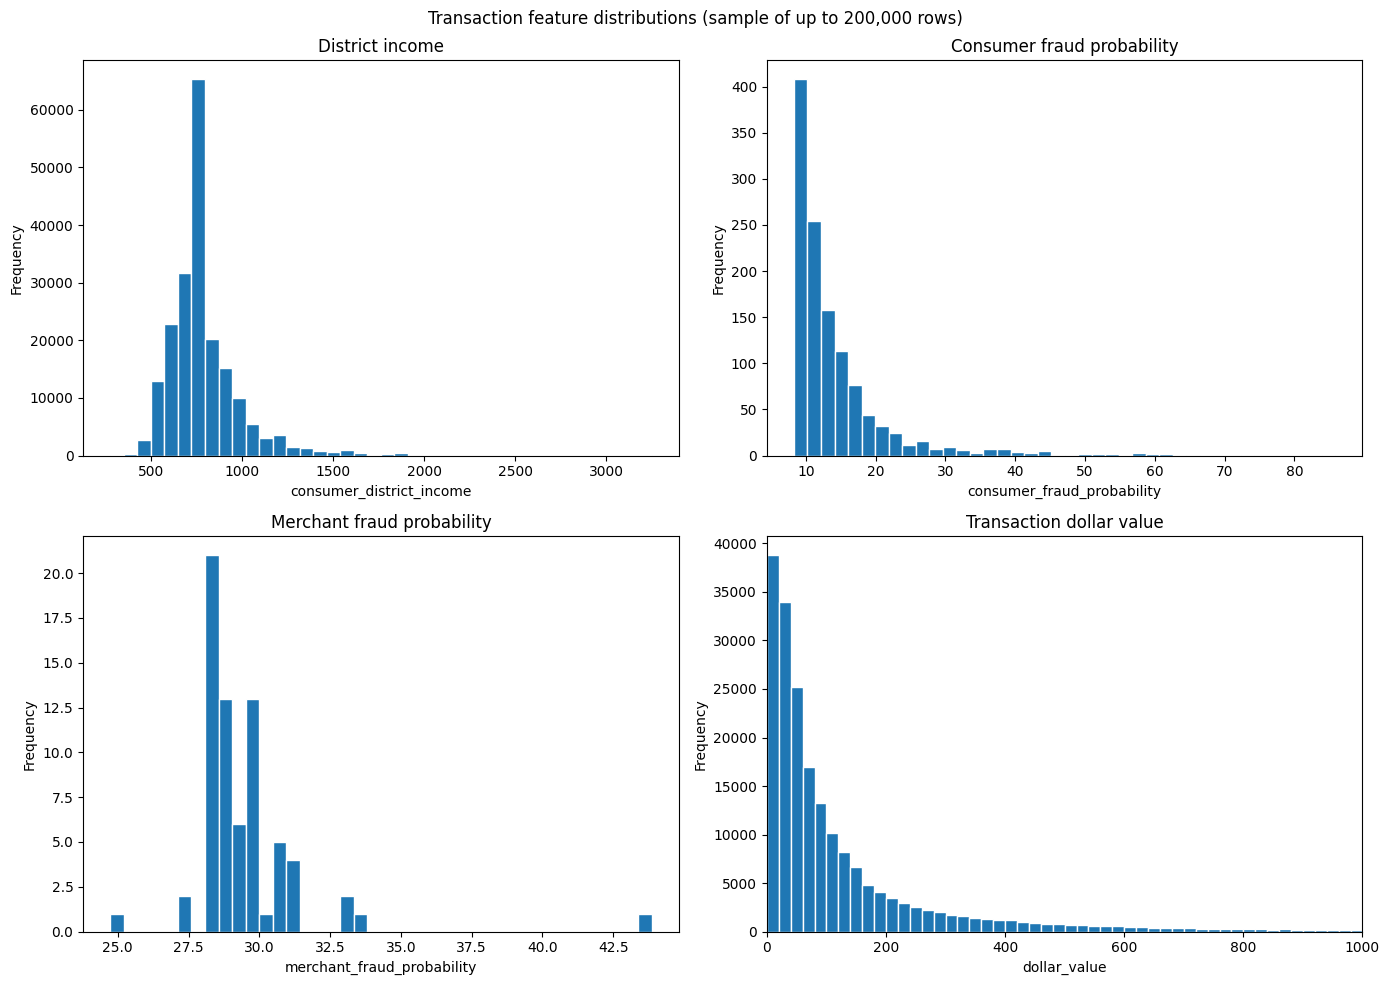

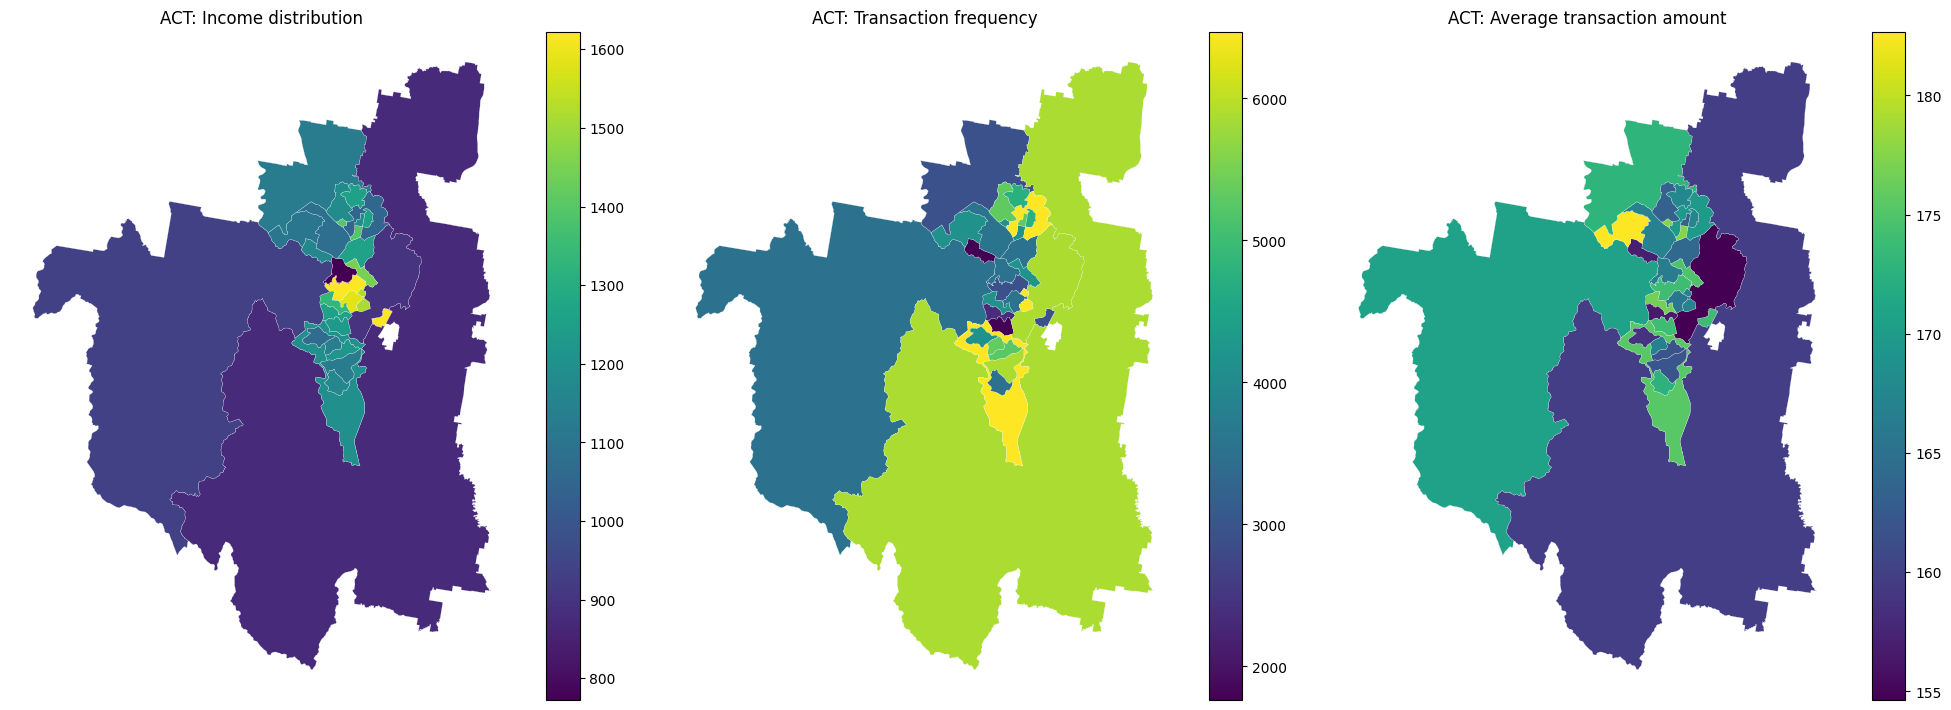

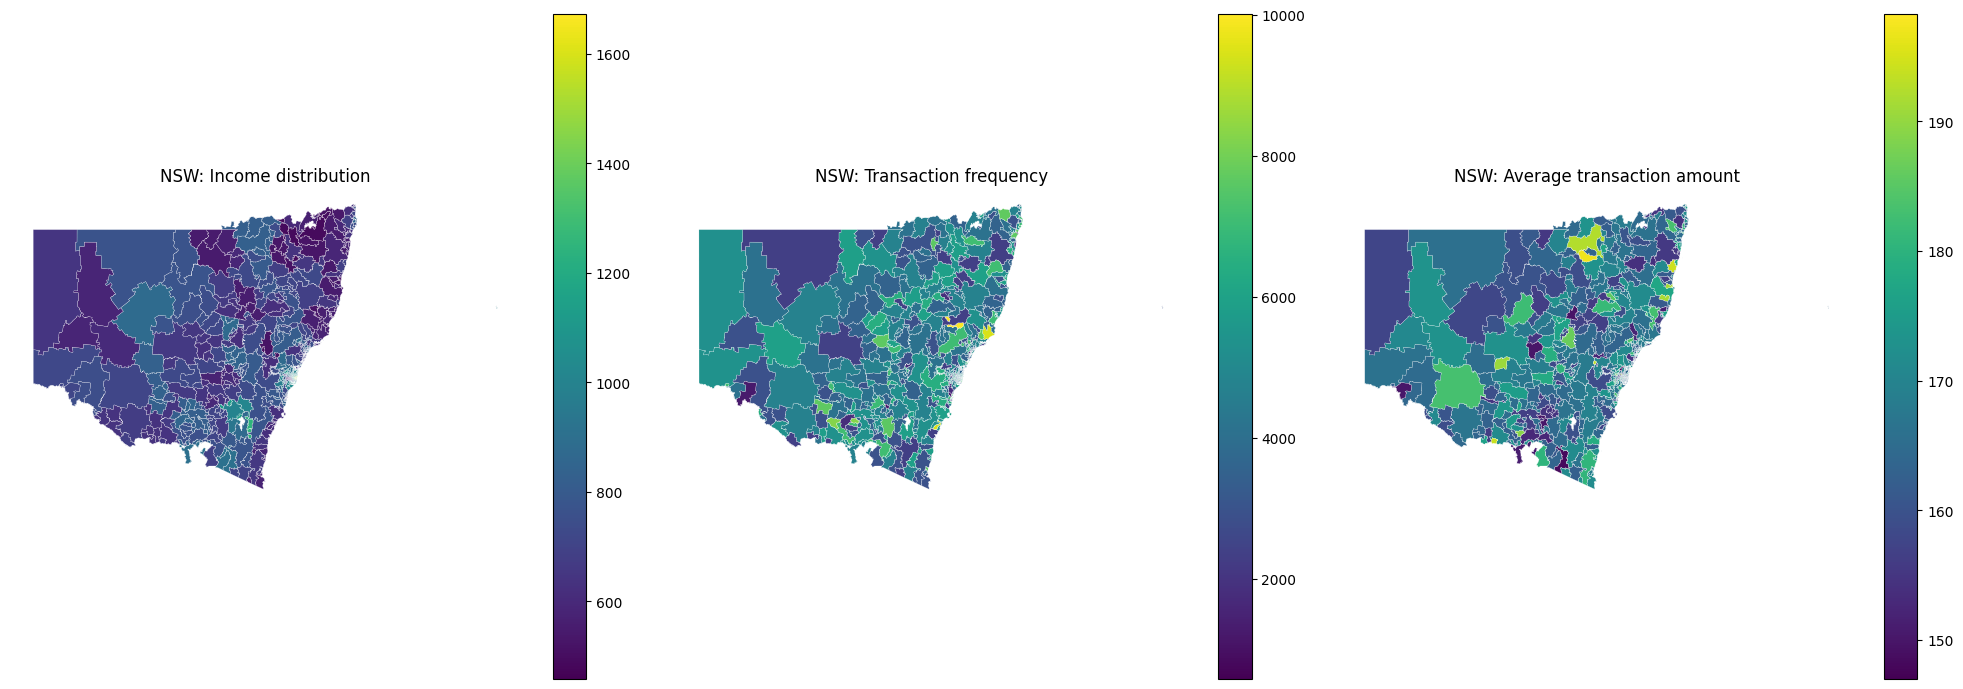

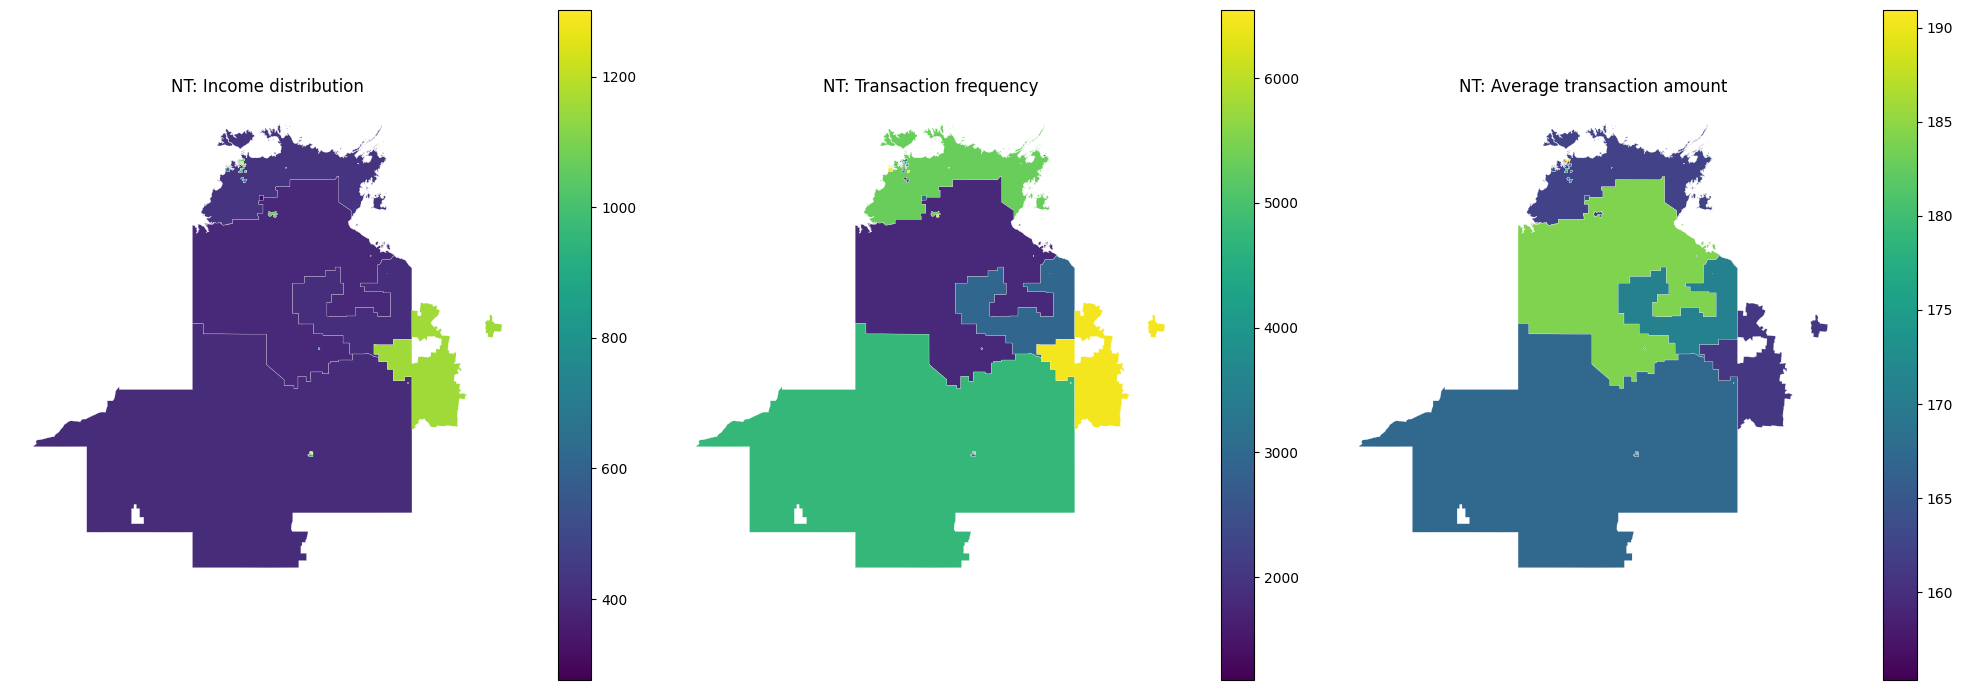

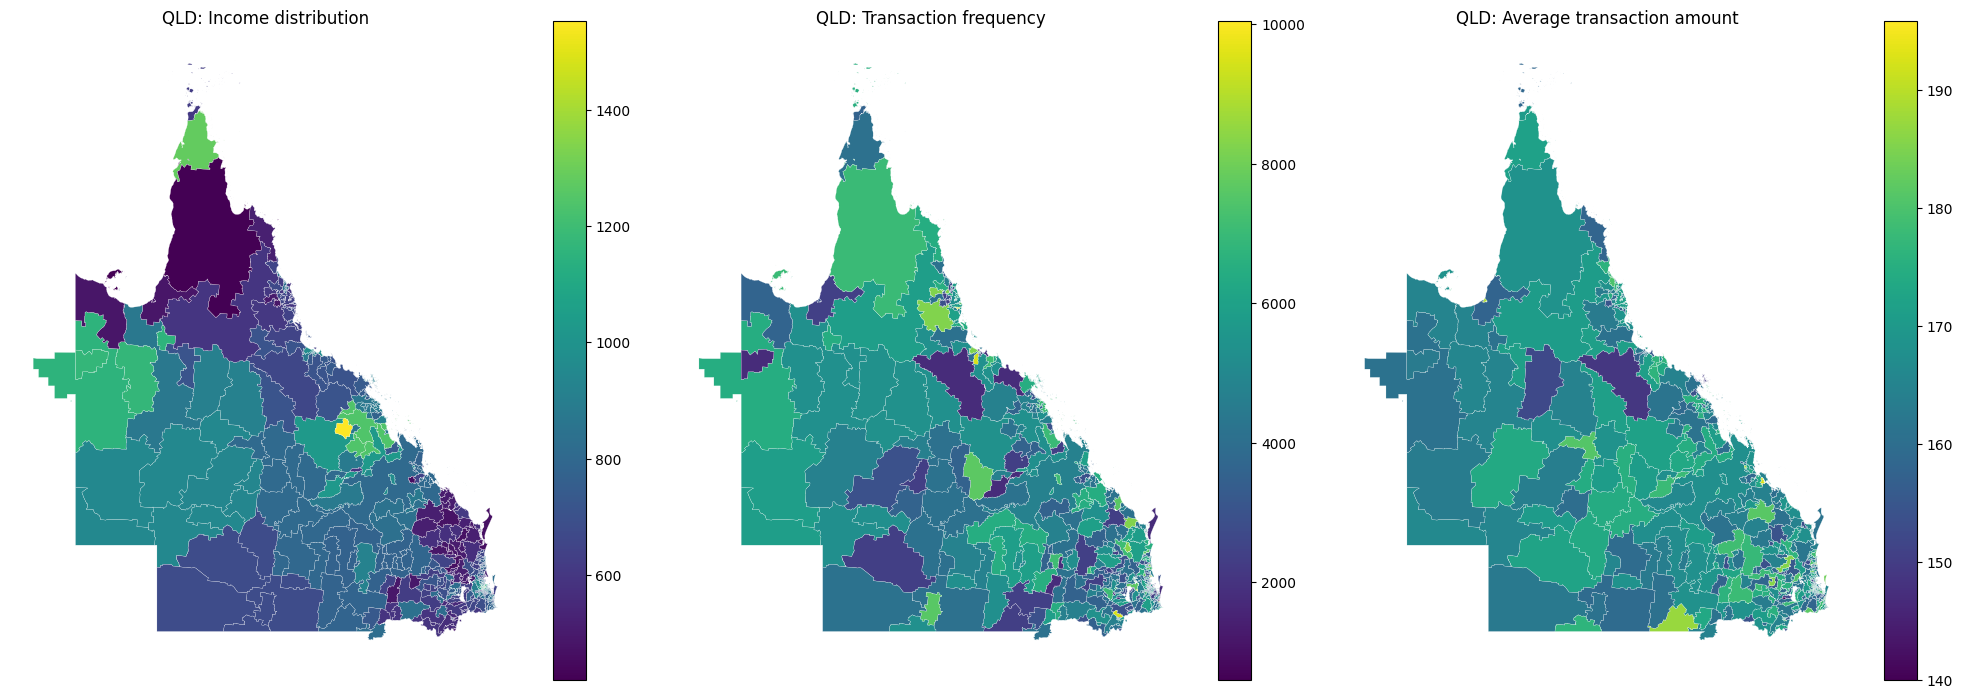

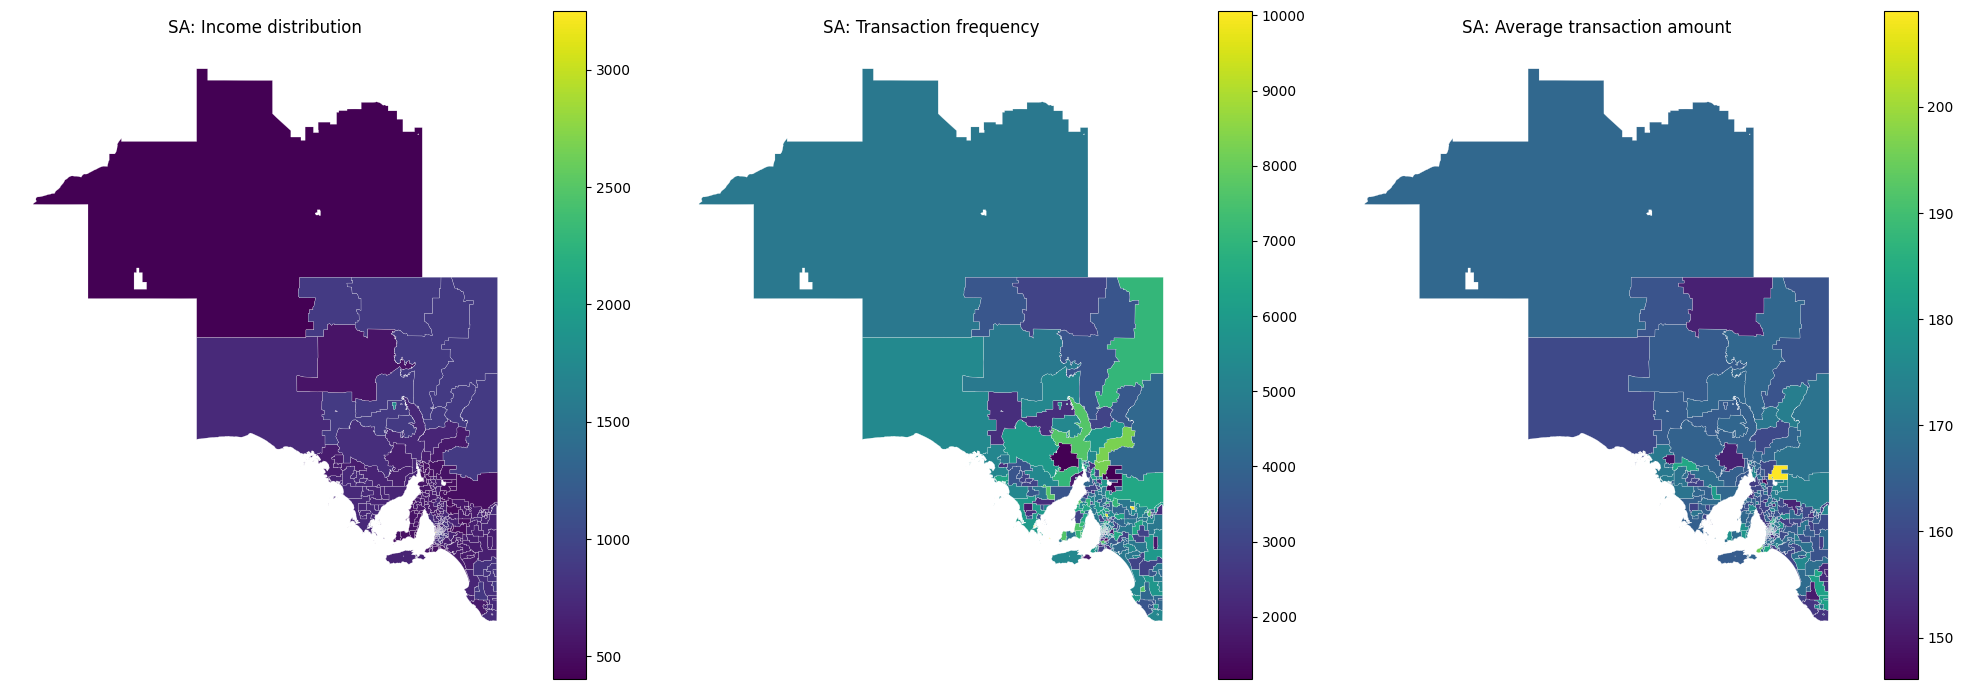

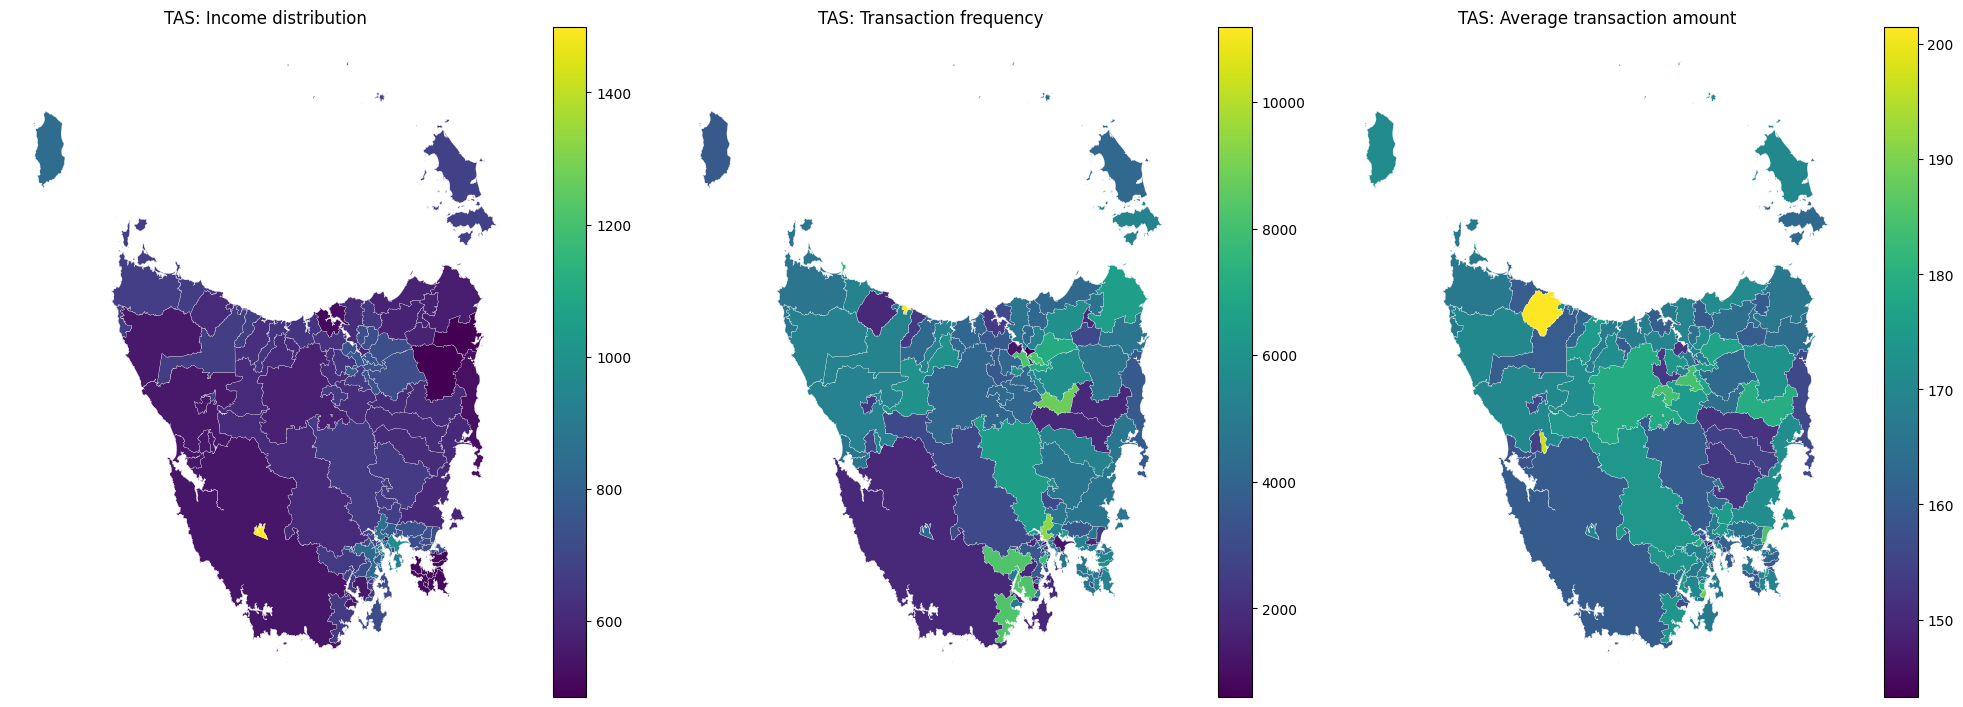

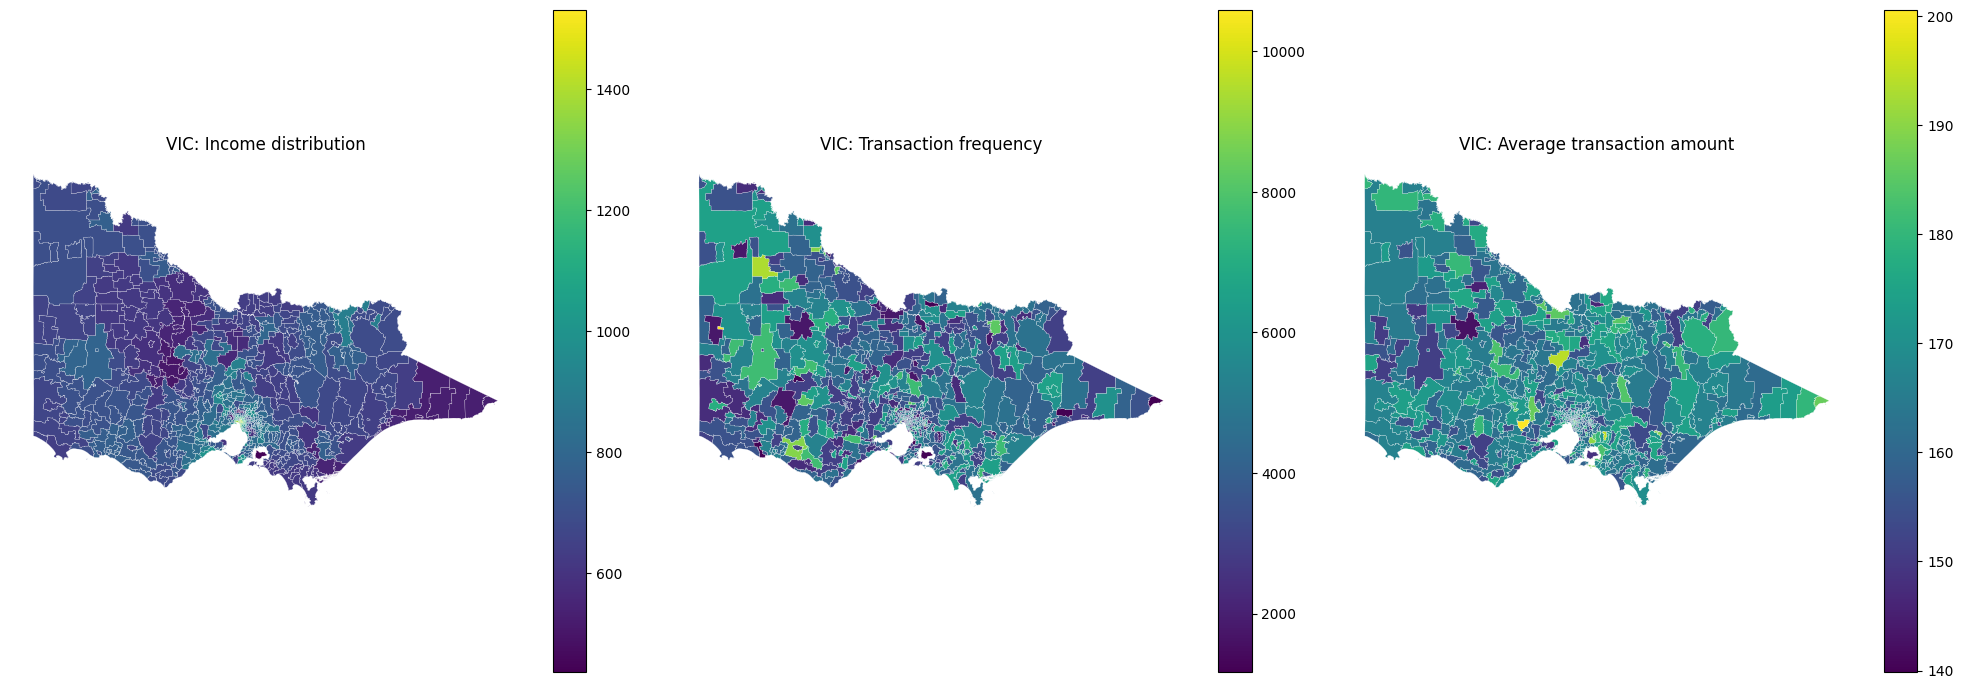

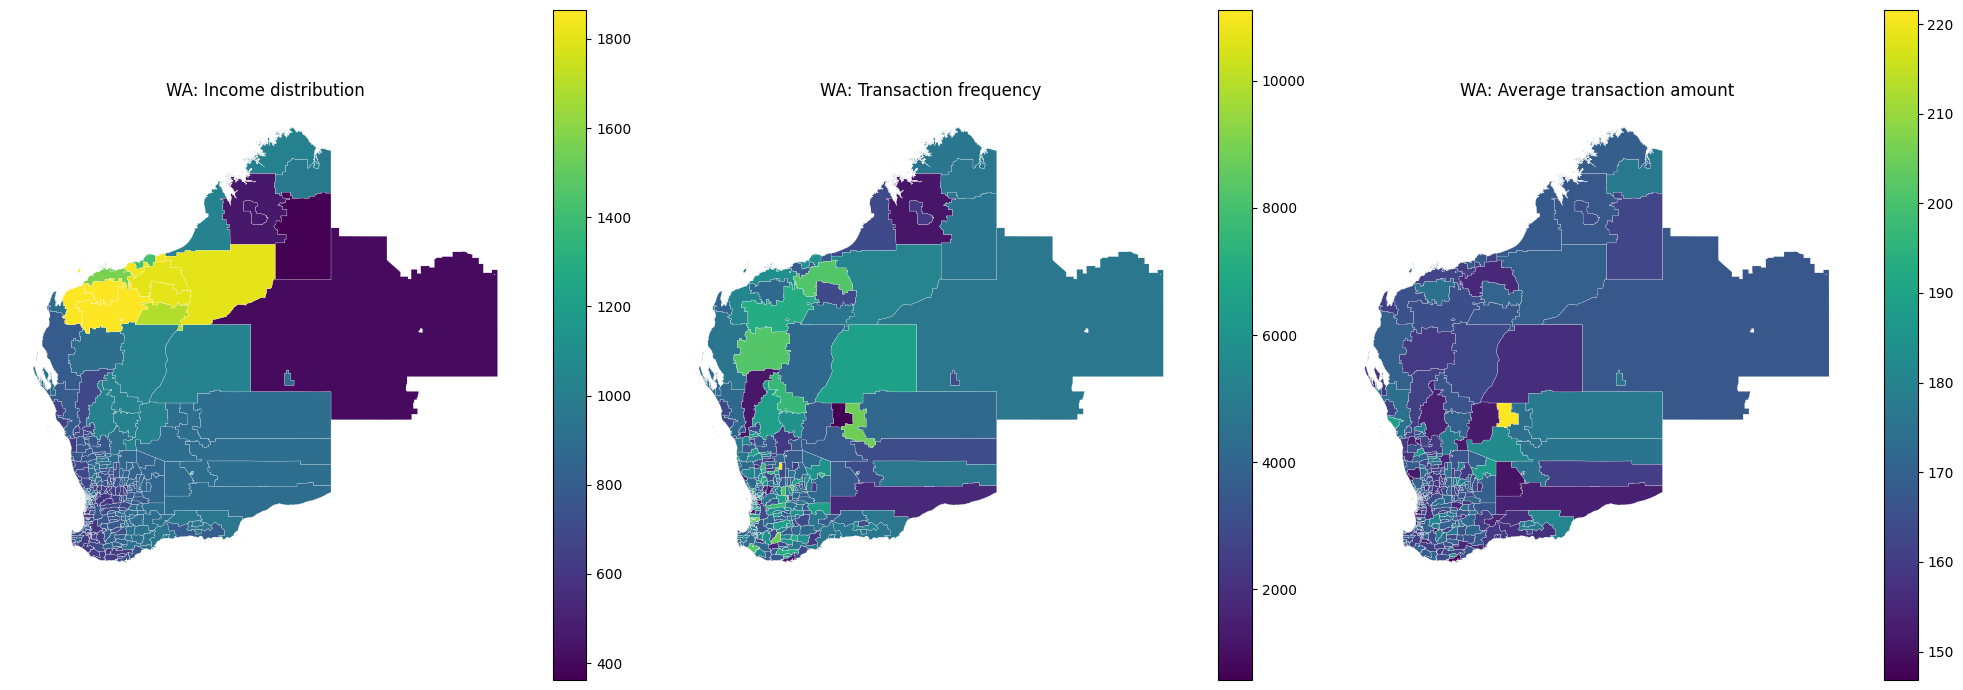

In [3]:
import geopandas as gpd
import matplotlib.pyplot as plt

transactions_for_plots = spark.read.parquet(str(root / "tables/curated/transactions"))

histogram_columns = {
    "consumer_district_income": "District income",
    "consumer_fraud_probability": "Consumer fraud probability",
    "merchant_fraud_probability": "Merchant fraud probability",
    "dollar_value": "Transaction dollar value",
}
histogram_sample = (transactions_for_plots.select(*histogram_columns)
                    .sample(withReplacement=False, fraction=0.02, seed=19)
                    .limit(200000).toPandas())
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for axis, (column, title) in zip(axes.flat, histogram_columns.items()):
    if column == "dollar_value":
        axis.hist(histogram_sample[column].dropna(), bins=50, range=(0, 1000), edgecolor="white")
        axis.set_xlim(0, 1000)
    else:
        axis.hist(histogram_sample[column].dropna(), bins=40, edgecolor="white")
    axis.set(title=title, xlabel=column, ylabel="Frequency")
fig.suptitle("Transaction feature distributions (sample of up to 200,000 rows)")
fig.tight_layout()
plt.show()

postcode_metrics = (transactions_for_plots
    .where(F.col("consumer_postcode").isNotNull())
    .groupBy("consumer_postcode")
    .agg(F.avg("consumer_district_income").alias("income_distribution"),
         F.count(F.lit(1)).alias("transaction_frequency"),
         F.avg("dollar_value").alias("average_transaction_amount")))
postcode_states = (spark.read.parquet(str(root / "tables/curated/postcode_income"))
    .select(F.col("postcode").alias("consumer_postcode"), "state").distinct())
postcode_metrics = postcode_metrics.join(postcode_states, "consumer_postcode", "left").toPandas()
postcode_metrics["consumer_postcode"] = postcode_metrics["consumer_postcode"].astype(str).str.zfill(4)

boundary_dir = root / "tables/landing/abs_2021/postal_areas_2021"
postal_areas_shapefile = next(boundary_dir.rglob("*.shp"))
postal_areas = gpd.read_file(postal_areas_shapefile)[["POA_CODE21", "geometry"]]
postal_areas["POA_CODE21"] = postal_areas["POA_CODE21"].astype(str).str.zfill(4)
mapped_postcodes = postal_areas.merge(postcode_metrics, left_on="POA_CODE21",
                                          right_on="consumer_postcode", how="inner")
map_columns = {
    "income_distribution": "Income distribution",
    "transaction_frequency": "Transaction frequency",
    "average_transaction_amount": "Average transaction amount",
}
for state in sorted(state for state in mapped_postcodes["state"].dropna().unique() if state != "OT"):
    state_map = mapped_postcodes[mapped_postcodes["state"] == state]
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    for axis, (column, title) in zip(axes, map_columns.items()):
        state_map.plot(column=column, ax=axis, cmap="viridis", legend=True,
                       edgecolor="white", linewidth=0.15)
        axis.set_title(f"{state}: {title}")
        axis.set_axis_off()
    fig.tight_layout()
    plt.show()

Transaction for each postcode

In [4]:
import math

summary_data = transactions_for_plots.select(
    F.col("consumer_district_income").alias("district_income"),
    F.col("dollar_value").alias("transaction_dollar_value")
)
summary_stats = summary_data.summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")

distribution_stats = summary_data.agg(
    F.count("district_income").alias("district_n"),
    F.avg("district_income").alias("district_mean"),
    F.stddev("district_income").alias("district_stddev"),
    F.count("transaction_dollar_value").alias("transaction_n"),
    F.avg("transaction_dollar_value").alias("transaction_mean"),
    F.stddev("transaction_dollar_value").alias("transaction_stddev")
).first()

district_threshold = math.sqrt(2 * math.log(distribution_stats["district_n"]))
transaction_threshold = math.sqrt(2 * math.log(distribution_stats["transaction_n"]))
outlier_counts = summary_data.agg(
    F.sum(F.when(
        F.abs((F.col("district_income") - distribution_stats["district_mean"]) / distribution_stats["district_stddev"]) > district_threshold, 1
    ).otherwise(0)).alias("district_income"),
    F.sum(F.when(
        F.abs((F.col("transaction_dollar_value") - distribution_stats["transaction_mean"]) / distribution_stats["transaction_stddev"]) > transaction_threshold, 1
    ).otherwise(0)).alias("transaction_dollar_value")
).first()

outlier_row = summary_stats.limit(1).select(
    F.lit("outlier_count").alias("summary"),
    F.lit(str(outlier_counts["district_income"])).alias("district_income"),
    F.lit(str(outlier_counts["transaction_dollar_value"])).alias("transaction_dollar_value")
)
print(f"Z-score thresholds — district income: {district_threshold:.4f}; transaction dollar value: {transaction_threshold:.4f}")
summary_stats.unionByName(outlier_row).show(truncate=False)

Z-score thresholds — district income: 5.7391; transaction dollar value: 5.7391


+-------------+-----------------+------------------------+
|summary      |district_income  |transaction_dollar_value|
+-------------+-----------------+------------------------+
|count        |14195505         |14195505                |
|mean         |785.1704245137919|166.2289539089168       |
|stddev       |195.7375149760775|517.8505602612779       |
|min          |276.0            |9.756658099412162E-8    |
|25%          |674.0            |26.127063654629243      |
|50%          |754.0179737922941|62.22398513124549       |
|75%          |843.0            |150.42286541417403      |
|max          |3250.0           |105193.88578925544      |
|outlier_count|3548             |46192                   |
+-------------+-----------------+------------------------+



## Consumer fraud: linear regression

The consumer/date scores are imputed in `01_etl.ipynb` using ordinary least squares (OLS) with an intercept and four fixed predictors:

- Same-day total spending, S.
- Same-day average order value, A.
- Squared same-day spending, S².
- Squared same-day order count, N².

The squared columns are formed before training-only standardisation. This is linear regression in its fitted coefficients, with polynomial input features. There is **no consumer hyperparameter search**: the feature set is fixed, the intercept is included, and there is no regularisation penalty. Coefficients and the intercept are learned by minimising squared errors; these are fitted parameters, not tuned hyperparameters. Predictions are clipped to the supplied 0–100 score scale.

The final OLS model is refitted on all **34,765 supplied consumer/date scores** and used to fill missing scores. On the existing chronological test period (10,133 labels), MAE is **1.9841**, RMSE **3.2557** percentage points, and R² **0.8855**. These results are saved in `tables/analysis/fraud_diagnostics/consumer_metrics.csv`. The same-day features make this a retrospective score estimate.


## Merchant GP: Matérn smoothness tuning

Compare **Matérn ν = 0.5, 1.5 and 2.5** using the existing four merchant/date predictors: same-day spending, order count, average order value and previous-30-day order count. Smaller ν allows rougher relationships; larger ν enforces smoother ones. This search varies smoothness only. Keep the shared length-scale structure, input/target transforms, optimizer settings and noise model fixed; signal strength, length scale and noise are still fitted on each training subset.

Use chronological validation: reserve the last 20% of unique scored dates, split the development dates into four blocks, and make three expanding training/validation folds. All preprocessing uses each fold's training data. Select by **mean validation RMSE**, weighting the folds equally; show MAE and R² as secondary metrics. That is **3 configurations × 3 folds = 9 candidate fits**.

After selection, compare the chosen ν with the previous ν=2.5 model and constant baselines on the existing final period. Refit the chosen GP on all 114 supplied scores and save it as `merchant_matern_retrospective_model.joblib`. This is a separate tuning result; the ETL's saved imputation table still uses its original GP. The feature set was selected previously, and the final period has been inspected before, so these are reused model-development benchmarks. Only 13 merchant/date scores are in that final period.

Run this section after ETL sections 11–15 have saved the feature tables. The helper cell below contains all required imports, date-splitting functions and metrics. Spark is not needed for this section.


In [5]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import pyarrow.dataset as ds
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def split_development_test(labels, test_fraction=0.2):
    """Reserve the last 20% of unique dates, matching the existing chronological benchmark."""
    if not 0 < test_fraction < 1:
        raise ValueError("test_fraction must be between zero and one.")
    dates = np.sort(labels.order_datetime.unique())
    boundary = int(len(dates) * (1 - test_fraction))
    if boundary < 4 or boundary >= len(dates):
        raise ValueError("Need at least four development dates and one final test date.")
    test_start = pd.Timestamp(dates[boundary])
    development = labels.loc[labels.order_datetime < test_start].reset_index(drop=True)
    test = labels.loc[labels.order_datetime >= test_start].reset_index(drop=True)
    return development, test, test_start

def make_expanding_folds(development, n_splits=3):
    """Split unique dates into four blocks; training expands before each validation block."""
    dates = np.sort(development.order_datetime.unique())
    if n_splits < 1 or len(dates) < n_splits + 1:
        raise ValueError("Insufficient dates for the requested expanding folds.")
    blocks = np.array_split(dates, n_splits + 1)
    folds = []
    for i in range(1, n_splits + 1):
        start, end = pd.Timestamp(blocks[i][0]), pd.Timestamp(blocks[i][-1])
        train = np.flatnonzero((development.order_datetime < start).to_numpy())
        valid = np.flatnonzero(development.order_datetime.between(start, end).to_numpy())
        if not len(train) or not len(valid):
            raise ValueError("An expanding fold has no training or validation rows.")
        folds.append({"name": f"fold_{i}", "train_indices": train, "validation_indices": valid})
    return folds

def score_metrics(actual, predicted):
    return {"mae": float(mean_absolute_error(actual, predicted)),
            "rmse": float(np.sqrt(mean_squared_error(actual, predicted))),
            "r2": float(r2_score(actual, predicted))}

import warnings
from scipy.special import expit, logit
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.impute import SimpleImputer

MERCHANT_FEATURES = ["same_day_spending", "same_day_order_count",
                     "same_day_average_order_value", "prior_30d_order_count"]
MATERN_SMOOTHNESS = [0.5, 1.5, 2.5]
_M_GP_NODES, _M_GP_WEIGHTS = np.polynomial.hermite.hermgauss(20)


def prepare_merchant_labels(frame):
    """Validate one supplied merchant/date target; never learn from imputed scores."""
    columns = ["merchant_abn", "order_datetime", "target_score", *MERCHANT_FEATURES]
    missing = set(columns) - set(frame.columns)
    if missing:
        raise ValueError(f"Missing merchant columns: {sorted(missing)}")
    result = frame[columns].copy()
    if result.empty or result[["merchant_abn", "order_datetime"]].isna().any().any():
        raise ValueError("Merchant modelling requires valid nonempty entity/date labels.")
    result["order_datetime"] = pd.to_datetime(result.order_datetime, errors="raise").dt.normalize()
    if result.duplicated(["merchant_abn", "order_datetime"]).any():
        raise ValueError("Merchant/date labels must be unique before splitting.")
    y = result.target_score.to_numpy(dtype=float)
    x = result[MERCHANT_FEATURES].to_numpy(dtype=float)
    if not np.isfinite(y).all() or not ((y >= 0) & (y <= 100)).all():
        raise ValueError("Only supplied finite 0–100 scores may train the GP.")
    if np.isinf(x).any() or (x < 0).any():
        raise ValueError("Merchant inputs must be nonnegative and finite or missing.")
    return result.sort_values(["order_datetime", "merchant_abn"]).reset_index(drop=True)


def fit_merchant_matern(frame, nu):
    """Change only Matérn smoothness; retain the ETL GP's other modelling choices."""
    if nu not in MATERN_SMOOTHNESS:
        raise ValueError("Use the approved smoothness values 0.5, 1.5 or 2.5.")
    if len(frame) < 10:
        raise ValueError("At least ten observed merchant/date rows are needed for this GP fit.")
    y = frame.target_score.to_numpy(dtype=float)
    raw = frame[MERCHANT_FEATURES].to_numpy(dtype=float)
    if not np.isfinite(y).all() or not ((y >= 0) & (y <= 100)).all():
        raise ValueError("Merchant training targets must be finite 0–100 scores.")
    if np.isinf(raw).any() or (raw < 0).any():
        raise ValueError("Merchant inputs must be nonnegative and finite or missing.")
    prep = Pipeline([
        ("impute", SimpleImputer(strategy="median", keep_empty_features=True)),
        ("scale", StandardScaler()),
    ]).fit(np.log1p(raw))
    kernel = (ConstantKernel(1.0, (1e-3, 1e3))
              * Matern(length_scale=1.0, length_scale_bounds=(1e-2, 1e3), nu=float(nu))
              + WhiteKernel(noise_level=0.1, noise_level_bounds=(1e-5, 10)))
    model = GaussianProcessRegressor(kernel=kernel, normalize_y=True, alpha=1e-8,
                                     n_restarts_optimizer=0, random_state=19)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        model.fit(prep.transform(np.log1p(raw)), logit(np.clip(y / 100, 1e-4, 1 - 1e-4)))
    return {"preprocessor": prep, "model": model, "nu": float(nu),
            "features": MERCHANT_FEATURES.copy(), "n_fit_rows": len(frame),
            "fit_warnings": [str(w.message) for w in caught]}


def predict_merchant_matern(bundle, frame):
    """Return bounded score means and conditional model intervals, aligned to input rows."""
    columns = ["predicted_score", "predicted_score_sd", "interval_low", "interval_high"]
    if frame.empty:
        return pd.DataFrame(index=frame.index, columns=columns, dtype=float)
    raw = frame[bundle["features"]].to_numpy(dtype=float)
    if np.isinf(raw).any() or (raw < 0).any():
        raise ValueError("Merchant inputs must be nonnegative and finite or missing.")
    x = bundle["preprocessor"].transform(np.log1p(raw))
    location, scale = bundle["model"].predict(x, return_std=True)
    draws = expit(location[:, None] + np.sqrt(2) * scale[:, None] * _M_GP_NODES)
    weights = _M_GP_WEIGHTS / np.sqrt(np.pi)
    mean = draws @ weights
    variance = np.maximum((draws ** 2) @ weights - mean ** 2, 0)
    return pd.DataFrame({
        "predicted_score": 100 * mean, "predicted_score_sd": 100 * np.sqrt(variance),
        "interval_low": 100 * expit(location - 1.959963984540054 * scale),
        "interval_high": 100 * expit(location + 1.959963984540054 * scale),
    }, index=frame.index)


def tune_merchant_matern(development, nu_values=(0.5, 1.5, 2.5)):
    """Select smoothness using three expanding development folds; no test rows enter."""
    if not nu_values or len(set(nu_values)) != len(nu_values):
        raise ValueError("Provide a nonempty set of distinct smoothness values.")
    if any(nu not in MATERN_SMOOTHNESS for nu in nu_values):
        raise ValueError("Smoothness candidates must come from the approved grid.")
    rows, fold_info = [], []
    for fold in make_expanding_folds(development):
        train = development.iloc[fold["train_indices"]]
        valid = development.iloc[fold["validation_indices"]]
        fold_info.append({"fold": fold["name"], "train_rows": len(train), "validation_rows": len(valid),
                          "train_first_date": str(train.order_datetime.min().date()),
                          "train_last_date": str(train.order_datetime.max().date()),
                          "validation_first_date": str(valid.order_datetime.min().date()),
                          "validation_last_date": str(valid.order_datetime.max().date())})
        for nu in nu_values:
            fitted = fit_merchant_matern(train, nu)
            prediction = predict_merchant_matern(fitted, valid)
            rows.append({"fold": fold["name"], "nu": float(nu),
                         **score_metrics(valid.target_score, prediction.predicted_score),
                         "kernel": str(fitted["model"].kernel_),
                         "fit_warnings": " | ".join(fitted["fit_warnings"])})
        print(f"Completed merchant {fold['name']}: {len(train)} training / {len(valid)} validation scores", flush=True)
    fold_results = pd.DataFrame(rows)
    tuning = (fold_results.groupby("nu", as_index=False)
              .agg(mean_rmse=("rmse", "mean"), std_rmse=("rmse", "std"),
                   mean_mae=("mae", "mean"), mean_r2=("r2", "mean"), folds=("fold", "nunique"))
              .sort_values(["mean_rmse", "mean_mae", "nu"]).reset_index(drop=True))
    tuning["rank"] = np.arange(1, len(tuning) + 1)
    tuning["selected"] = tuning["rank"] == 1
    return tuning, fold_results, pd.DataFrame(fold_info)


def run_merchant_matern(root):
    """Tune smoothness, compare the selected model with ν=2.5, then save an all-label fit."""
    root = Path(root)
    output = root / "tables/analysis/fraud_diagnostics"
    output.mkdir(parents=True, exist_ok=True)
    dataset = ds.dataset(root / "tables/analysis/merchant_score_features", format="parquet")
    labels = prepare_merchant_labels(dataset.to_table(
        columns=["merchant_abn", "order_datetime", "target_score", *MERCHANT_FEATURES],
        filter=ds.field("target_score").is_valid()).to_pandas())
    development, test, test_start = split_development_test(labels)
    tuning, folds, fold_info = tune_merchant_matern(development)
    best_nu = float(tuning.iloc[0].nu)
    print("Selected merchant Matérn smoothness:", best_nu, flush=True)

    # Selection is frozen before evaluating either model on final-period targets.
    test_fits = {nu: fit_merchant_matern(development, nu) for nu in sorted({best_nu, 2.5})}
    metric_rows, holdouts = [], []
    for name, nu in [("selected_matern_gp", best_nu), ("previous_matern_2.5", 2.5)]:
        prediction = predict_merchant_matern(test_fits[nu], test)
        metric_rows.append({"split": "test", "model": name, "nu": nu,
                            "train_rows": len(development), "test_rows": len(test),
                            **score_metrics(test.target_score, prediction.predicted_score)})
        record = test[["merchant_abn", "order_datetime", "target_score"]].join(prediction)
        record["model"], record["nu"], record["split"] = name, nu, "test"
        holdouts.append(record)
    for name, estimate in [("training_mean", development.target_score.mean()),
                           ("training_median", development.target_score.median())]:
        metric_rows.append({"split": "test", "model": name, "nu": None,
                            "train_rows": len(development), "test_rows": len(test),
                            **score_metrics(test.target_score, np.full(len(test), estimate))})
    metrics = pd.DataFrame(metric_rows)
    previous_path = output / "merchant_metrics.csv"
    if previous_path.exists():
        previous = pd.read_csv(previous_path)
        previous = previous.loc[(previous.split == "test") & (previous.model == "gaussian_process")]
        if len(previous) == 1:
            reproduced = metrics.loc[metrics.model == "previous_matern_2.5"].iloc[0]
            if int(previous.iloc[0].test_rows) != len(test) or not np.allclose(
                    previous.iloc[0][["mae", "rmse", "r2"]].to_numpy(dtype=float),
                    reproduced[["mae", "rmse", "r2"]].to_numpy(dtype=float), rtol=1e-7, atol=1e-7):
                raise AssertionError("The ν=2.5 comparison does not reproduce the existing GP benchmark.")

    paths = {key: str(output / name) for key, name in {
        "tuning": "merchant_matern_tuning.csv", "fold_results": "merchant_matern_fold_metrics.csv",
        "folds": "merchant_matern_folds.csv", "metrics": "merchant_matern_metrics.csv",
        "holdouts": "merchant_matern_holdout_predictions.parquet",
        "model": "merchant_matern_retrospective_model.joblib", "summary": "merchant_matern_summary.json",
    }.items()}
    for key, frame in [("tuning", tuning), ("fold_results", folds), ("folds", fold_info), ("metrics", metrics)]:
        frame.to_csv(paths[key], index=False)
    pd.concat(holdouts, ignore_index=True).to_parquet(paths["holdouts"], index=False)
    final_fit = fit_merchant_matern(labels, best_nu)
    final_fit.update(fit_scope="all_labels_retrospective", labelled_rows=len(labels),
                     training_first_date=str(labels.order_datetime.min().date()),
                     training_last_date=str(labels.order_datetime.max().date()))
    joblib.dump(final_fit, paths["model"])
    summary = {
        "model": "GaussianProcessRegressor", "features": MERCHANT_FEATURES,
        "nu_grid": MATERN_SMOOTHNESS, "selected_nu": best_nu,
        "candidates": len(tuning), "folds": 3, "candidate_fits": len(folds),
        "selection": "Lowest unweighted mean validation RMSE across three expanding chronological folds.",
        "fixed_choices": "Four existing features, log1p, training-median imputation/scaling, logit target, shared length scale, Matérn plus WhiteKernel, alpha=1e-8, no optimizer restarts, seed=19.",
        "fitted_parameters": "Signal amplitude, common length scale and noise optimized on each training subset.",
        "development_rows": len(development), "test_rows": len(test), "labelled_rows": len(labels),
        "test_start": str(test_start.date()), "tuning_results": tuning.to_dict("records"),
        "test_metrics": metrics.to_dict("records"), "final_kernel": str(final_fit["model"].kernel_),
        "final_fit_warnings": final_fit["fit_warnings"],
        "final_fit_scope": "All supplied labels after evaluation; separate tuned GP model artifact.",
        "imputation_table_model": "ETL effective merchant scores still use its original fixed-nu=2.5 model.",
        "limitations": [
            "There are only 114 supplied merchant/date scores; the final period has 13.",
            "Previously selected features are fixed; validation scores are reused model-development evidence.",
            "The previously inspected final period is a reused benchmark and is excluded from this smoothness search.",
            "Conditional GP intervals are not empirically calibrated transaction-fraud probabilities.",
        ], "paths": paths,
    }
    # Convert missing baseline nu to JSON null rather than non-standard NaN.
    for record in summary["test_metrics"]:
        if pd.isna(record["nu"]):
            record["nu"] = None
    Path(paths["summary"]).write_text(json.dumps(summary, indent=2, allow_nan=False) + "\n")
    return summary


In [6]:
merchant_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / "tables/analysis/merchant_score_features").is_dir()), None)
if merchant_root is None:
    raise FileNotFoundError("Run from industry-project-group-19 or code/ after ETL sections 11–15.")

merchant_matern_summary = run_merchant_matern(merchant_root)
merchant_output = merchant_root / "tables/analysis/fraud_diagnostics"
print("Merchant chronological validation folds:")
display(pd.read_csv(merchant_matern_summary["paths"]["folds"]))
print("Matérn smoothness ranked by mean validation RMSE:")
display(pd.read_csv(merchant_matern_summary["paths"]["tuning"]))
print("Individual fold results:")
display(pd.read_csv(merchant_matern_summary["paths"]["fold_results"])[["fold", "nu", "mae", "rmse", "r2"]])
print("Final-period benchmark after smoothness selection:")
display(pd.read_csv(merchant_matern_summary["paths"]["metrics"]))
print(f"Saved selected GP refitted on {merchant_matern_summary['labelled_rows']} supplied merchant/date scores.")


Completed merchant fold_1: 16 training / 15 validation scores


Completed merchant fold_2: 31 training / 51 validation scores


Completed merchant fold_3: 82 training / 19 validation scores


Selected merchant Matérn smoothness: 2.5


Merchant chronological validation folds:


...

Individual fold results:


,fold,nu,mae,rmse,r2
0,fold_1,0.5,18.138657,20.228832,-0.198069
1,fold_1,1.5,18.593439,20.890590,-0.277737
2,fold_1,2.5,18.714526,21.080379,-0.301059
3,fold_2,0.5,11.989521,13.479137,0.078197
4,fold_2,1.5,11.947895,13.477653,0.078400
5,fold_2,2.5,11.967433,13.499201,0.075451
6,fold_3,0.5,7.936270,10.661144,0.656337
7,fold_3,1.5,7.145085,9.748982,0.712629
8,fold_3,2.5,6.932480,9.522378,0.725833


Final-period benchmark after smoothness selection:


,split,model,nu,train_rows,test_rows,mae,rmse,r2
0,test,selected_matern_gp,2.5,101,13,11.304290,14.261936,0.407405
1,test,previous_matern_2.5,2.5,101,13,11.304290,14.261936,0.407405
2,test,training_mean,NaN,101,13,14.512487,18.560643,-0.003662
3,test,training_median,NaN,101,13,12.189001,19.818173,-0.144270


Saved selected GP refitted on 114 supplied merchant/date scores.


## Merchant Matérn hyperparameter plot

The three bars compare smoothness ν=0.5, 1.5 and 2.5 by mean validation RMSE; the selected setting is highlighted. The plot uses the three chronological development folds, with lower values better. Test errors do not select configurations or enter this plot.

The merchant comparison uses only 101 development scores, with 16/31/82 training rows in successive folds, so differences between settings are uncertain. PNG and SVG copies are saved under `tables/analysis/fraud_diagnostics/figures/`.

**Recorded result:** ν=2.5 has mean validation RMSE 14.7007, versus 14.7057 for ν=1.5 and 14.7897 for ν=0.5 (percentage points). These differences are small relative to variation between folds, so there is no convincing improvement from changing smoothness. The selected setting remains the original ν=2.5, reproducing final-period RMSE 14.2619 and R² 0.4074. In the first fold (16 training scores), all three fits reached the noise lower bound; these warnings are saved in the fold-results CSV. The all-114-label refit emitted no convergence warnings.


In [7]:
"""Plot saved merchant smoothness validation results without reading test predictions."""

from pathlib import Path

import numpy as np
import pandas as pd


def _selected_mask(values):
    """Read the selected-candidate flag consistently from a CSV."""
    return values.astype(str).str.strip().str.lower().isin(["true", "1", "1.0"])


def _read_merchant_plot_inputs(output_dir):
    """Read and validate merchant validation results before writing the figure."""
    merchant_tuning = pd.read_csv(output_dir / "merchant_matern_tuning.csv")
    missing = {"nu", "mean_rmse", "selected"}.difference(merchant_tuning.columns)
    if missing:
        raise ValueError(f"Merchant tuning table is missing columns: {sorted(missing)}")
    if merchant_tuning.empty:
        raise ValueError("Merchant tuning table has no candidates.")
    for column in ["nu", "mean_rmse"]:
        merchant_tuning[column] = pd.to_numeric(merchant_tuning[column], errors="raise")
    if not np.isfinite(merchant_tuning[["nu", "mean_rmse"]]).all().all():
        raise ValueError("Merchant tuning values must be finite.")
    if (merchant_tuning.mean_rmse < 0).any():
        raise ValueError("Merchant validation RMSE must be nonnegative.")
    if merchant_tuning.nu.duplicated().any() or set(merchant_tuning.nu) != {0.5, 1.5, 2.5}:
        raise ValueError("Merchant tuning table must contain one row each for nu=0.5, 1.5 and 2.5.")
    if _selected_mask(merchant_tuning.selected).sum() != 1:
        raise ValueError("Merchant tuning table must mark exactly one selected candidate.")
    merchant_tuning = merchant_tuning.sort_values("nu").reset_index(drop=True)
    return merchant_tuning


def _save_figure(figure, directory, stem):
    """Save the same layout as a raster image and an editable vector image."""
    paths = {}
    for suffix in ["png", "svg"]:
        destination = directory / f"{stem}.{suffix}"
        figure.savefig(destination, dpi=180, bbox_inches="tight", facecolor="white")
        paths[f"{stem}_{suffix}"] = str(destination)
    return paths


def plot_merchant_matern(output_dir: Path) -> dict[str, str]:
    """Save a comparison of the three smoothness values using mean validation RMSE.

    Read merchant_matern_tuning.csv; return PNG/SVG paths. The highlighted
    setting was selected on development folds, with test predictions excluded.
    """
    import matplotlib.pyplot as plt

    output_dir = Path(output_dir)
    merchant_tuning = _read_merchant_plot_inputs(output_dir)
    figure_dir = output_dir / "figures"
    figure_dir.mkdir(parents=True, exist_ok=True)
    paths = {}
    style = {
        "font.family": "DejaVu Sans",
        "font.size": 10,
        "axes.titlesize": 15,
        "axes.titleweight": "semibold",
        "axes.labelsize": 11,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#A1A9B0",
        "axes.labelcolor": "#263442",
        "text.color": "#263442",
        "xtick.color": "#52606D",
        "ytick.color": "#52606D",
        "svg.fonttype": "none",
    }
    with plt.rc_context(style):
        figure, axis = plt.subplots(figsize=(8.5, 5.3))
        try:
            positions = np.arange(len(merchant_tuning))
            values = merchant_tuning.mean_rmse.to_numpy(dtype=float)
            selected_merchant = _selected_mask(merchant_tuning.selected).to_numpy(dtype=bool)
            selected_position = int(np.flatnonzero(selected_merchant)[0])
            selected_nu = float(merchant_tuning.loc[selected_position, "nu"])
            scale = max(float(values.max()), 1.0)
            colours = np.where(selected_merchant, "#217C80", "#BAC7D1")
            axis.bar(positions, values, width=0.56, color=colours, zorder=2)
            for position, value in zip(positions, values):
                axis.text(position, value + scale * 0.025, f"{value:.2f}",
                          ha="center", va="bottom", fontsize=11, fontweight="semibold")
            axis.scatter(
                [selected_position], [values[selected_position] + scale * 0.13],
                marker="*", s=190, color="#182A3A", edgecolor="white", linewidth=0.8,
                zorder=4, label=f"Selected: ν={selected_nu:g}",
            )
            axis.set_xticks(positions, [f"{nu:g}" for nu in merchant_tuning.nu])
            axis.set_xlim(-0.65, len(positions) - 0.35)
            axis.set_ylim(0, scale * 1.3)
            axis.set_xlabel("Matérn smoothness (ν)")
            axis.set_ylabel("Mean validation RMSE (score points)")
            axis.set_title("Merchant Matérn smoothness comparison", loc="left", pad=29)
            axis.text(0, 1.025, "Three expanding chronological validation folds",
                      transform=axis.transAxes, color="#52606D", fontsize=10)
            axis.grid(axis="y", color="#E5E9ED", linewidth=0.8)
            axis.set_axisbelow(True)
            axis.legend(loc="upper right", frameon=False, fontsize=10)
            figure.text(0.125, 0.015, "Lower RMSE is better. Only smoothness changes; test scores are excluded.",
                        color="#52606D", fontsize=9)
            figure.subplots_adjust(top=0.83, bottom=0.15)
            paths.update(_save_figure(figure, figure_dir, "merchant_matern_tuning"))
        finally:
            plt.close(figure)
    return paths


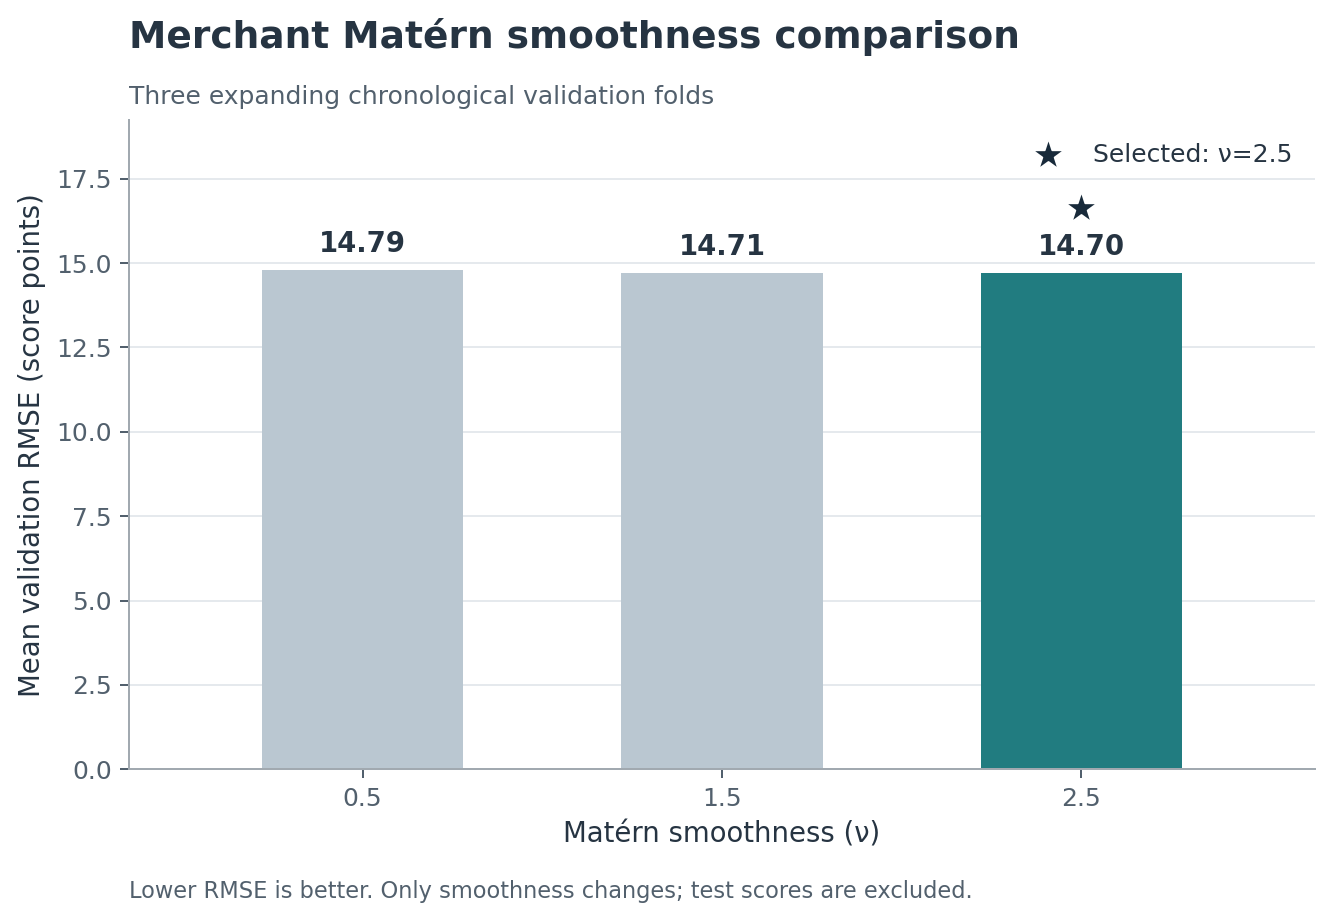

PNG and SVG tuning figure saved in /Users/trollinmaster/Documents/Uni/Coding/VSCode/MAST30034/industry-project-group-19/tables/analysis/fraud_diagnostics/figures


In [8]:
from IPython.display import Image, display

merchant_plot_paths = plot_merchant_matern(merchant_output)
display(Image(filename=merchant_plot_paths["merchant_matern_tuning_png"], width=850))
print("PNG and SVG tuning figure saved in", merchant_output / "figures")


## Transaction UMAP: supplied versus missing fraud scores

Include **every transaction with either original supplied fraud score**, plus a reproducible sample of **50,000 transactions missing both scores**. One point is one order, so a consumer/date or merchant/date score can appear on several points. In each panel, blue means that panel's original score was supplied; grey means it was missing, even if the other score was supplied. Imputed fraud scores are never treated as observed.

The two panels share one UMAP fitted on transaction value, consumer daily spending/average order value/order count, and merchant daily spending/average order value/order count/previous-30-day order count. These are the current project's activity inputs; the reference image used a different set of consumer-history inputs. Squared consumer terms are omitted because their raw quantities are already represented. Scores, score-availability flags, predictions, IDs and calendar dates are excluded from the embedding. Numeric features use `log1p`, median imputation with feature-missingness indicators, then standardisation on the retained sample.

Use **30 neighbours, minimum distance 0.15, Euclidean distance, 200 epochs and seed 1902**. These are fixed visualisation settings, not fraud-model hyperparameters. Both the seeded sampling and UMAP settings are saved. Matching inputs/code/settings reuse saved coordinates. Requires `duckdb` and `umap-learn` in the notebook kernel (`%pip install duckdb==1.5.5 umap-learn==0.5.12` if needed); the code below runs without Spark.

### Interpreting missingness

- **MCAR:** missingness is independent of observed and unobserved values. Differences in availability across observed activity or dates argue against this; overlapping colours do not establish MCAR.
- **MAR:** after accounting for observed information, missingness no longer depends on the missing score itself.
- **MNAR:** dependence on the missing score remains after accounting for observed information. The observed data alone cannot distinguish MAR from MNAR ([National Research Council](https://www.ncbi.nlm.nih.gov/books/NBK209895/)).

This is exploratory evidence, not a formal MCAR/MAR/MNAR test. UMAP can distort density and create apparent gaps ([UMAP documentation](https://umap-learn.readthedocs.io/en/latest/clustering.html)). Supplied scores are deliberately oversampled, and transaction-level labels repeat within entity/date. Therefore use the accompanying **full-population** month and amount coverage tables to assess associations; do not use the plotted blue/grey proportions as population coverage. Amount profiles also split the consumer label date window from later/earlier dates. Sampling probabilities and population weights are saved for future analyses; the UMAP itself is unweighted.


In [9]:
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import tempfile
import time
import duckdb
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

TRANSACTION_UMAP_FEATURES = [
    "dollar_value", "consumer_day_spending", "consumer_day_average_order_value",
    "consumer_day_order_count", "merchant_day_spending",
    "merchant_day_average_order_value", "merchant_day_order_count",
    "merchant_prior_30d_order_count",
]
TRANSACTION_UMAP_SETTINGS = dict(n_neighbors=30, min_dist=0.15, n_components=2,
                                 metric="euclidean", n_epochs=200, n_jobs=1,
                                 low_memory=True)


def load_transaction_umap_sample(root, background_size=50_000, seed=1902):
    """Keep every originally scored order and a deterministic sample missing both scores."""
    root = Path(root)
    if not isinstance(background_size, int) or background_size < 1:
        raise ValueError("background_size must be a positive integer.")
    known = "(consumer_fraud_probability IS NOT NULL OR merchant_fraud_probability IS NOT NULL)"
    with tempfile.TemporaryDirectory(prefix="bnpl-umap-") as scratch, duckdb.connect() as con:
        con.execute("SET memory_limit='1GB'")
        con.execute("SET threads=4")
        con.execute("SET temp_directory=?", [scratch])
        for view, directory in [
            ("transactions", "tables/curated/transactions"),
            ("consumer_daily", "tables/analysis/consumer_score_features"),
            ("merchant_daily", "tables/analysis/merchant_score_features"),
        ]:
            con.read_parquet(str(root / directory / "**/*.parquet")).create_view(view)
        counts = con.execute(f"""SELECT count(*) AS population_rows,
            count(consumer_fraud_probability) AS all_consumer_supplied_rows,
            count(merchant_fraud_probability) AS all_merchant_supplied_rows,
            count(*) FILTER (WHERE {known}) AS all_supplied_transaction_rows,
            count(*) FILTER (WHERE NOT {known}) AS unscored_population_rows,
            count(DISTINCT (user_id, order_datetime)) FILTER
                (WHERE consumer_fraud_probability IS NOT NULL) AS consumer_supplied_entity_dates,
            count(DISTINCT (merchant_abn, order_datetime)) FILTER
                (WHERE merchant_fraud_probability IS NOT NULL) AS merchant_supplied_entity_dates
            FROM transactions""").fetchdf().iloc[0].astype(int).to_dict()
        if not counts["population_rows"] or not counts["all_supplied_transaction_rows"]:
            raise ValueError("Need transactions with supplied scores.")
        for entity in ["consumer", "merchant"]:
            field = entity + "_fraud_probability"
            invalid = con.execute(f"""SELECT count(*) FROM transactions
                WHERE {field} IS NOT NULL AND (NOT isfinite({field}) OR {field}<0 OR {field}>100)""").fetchone()[0]
            if invalid:
                raise ValueError(f"Invalid supplied {entity} probabilities.")
            n_labels = con.execute(f"SELECT count(target_score) FROM {entity}_daily").fetchone()[0]
            if n_labels != counts[f"{entity}_supplied_entity_dates"]:
                raise ValueError(f"Some supplied {entity}/date labels have no matched transaction.")

        # These profiles use the entire population, never the enriched UMAP sample.
        aggregates = """count(*) AS transaction_rows,
            count(consumer_fraud_probability) AS consumer_supplied_rows,
            count(merchant_fraud_probability) AS merchant_supplied_rows"""
        by_month = con.execute(f"""SELECT strftime(order_datetime, '%Y-%m') AS month,
            {aggregates} FROM transactions GROUP BY month ORDER BY month""").fetchdf()
        by_amount = con.execute(f"""WITH binned AS (
            SELECT *, CASE WHEN dollar_value IS NULL OR NOT isfinite(dollar_value) THEN 0
                WHEN dollar_value < 50 THEN 1 WHEN dollar_value < 100 THEN 2
                WHEN dollar_value < 250 THEN 3 WHEN dollar_value < 500 THEN 4
                WHEN dollar_value < 1000 THEN 5 WHEN dollar_value < 2000 THEN 6
                WHEN dollar_value < 5000 THEN 7 ELSE 8 END AS amount_bin,
                CASE WHEN order_datetime <= (SELECT max(order_datetime) FROM consumer_daily
                                                WHERE target_score IS NOT NULL)
                     AND order_datetime >= (SELECT min(order_datetime) FROM consumer_daily
                                                WHERE target_score IS NOT NULL)
                     THEN 'Within consumer supplied-date window' ELSE 'Outside consumer supplied-date window' END AS period
            FROM transactions)
            SELECT period, amount_bin, {aggregates} FROM binned
            GROUP BY period, amount_bin ORDER BY period, amount_bin""").fetchdf()
        amount_labels = {0: "Missing/nonfinite", 1: "Below $50", 2: "$50–<100",
                         3: "$100–<250", 4: "$250–<500", 5: "$500–<1,000",
                         6: "$1,000–<2,000", 7: "$2,000–<5,000", 8: "$5,000+"}
        by_amount["amount_range"] = by_amount.amount_bin.map(amount_labels)
        for profile in [by_month, by_amount]:
            for entity in ["consumer", "merchant"]:
                profile[f"{entity}_supplied_pct"] = 100 * profile[f"{entity}_supplied_rows"] / profile.transaction_rows

        columns = "order_id, user_id, merchant_abn, order_datetime, dollar_value, consumer_fraud_probability, merchant_fraud_probability"
        con.execute(f"""CREATE TEMP TABLE sampled_background AS SELECT {columns},
            hash(order_id, CAST(? AS BIGINT)) AS sampling_priority
            FROM transactions WHERE NOT {known}
            ORDER BY sampling_priority, order_id LIMIT ?""", [seed, background_size])
        con.execute(f"""CREATE TEMP TABLE selected_orders AS
            SELECT {columns}, hash(order_id, CAST(? AS BIGINT)) AS sampling_priority,
                'all supplied-score orders' AS selection_source
            FROM transactions WHERE {known}
            UNION ALL SELECT *, 'sampled both-missing orders' AS selection_source FROM sampled_background""", [seed])
        data = con.execute("""SELECT s.*,
            c.same_day_spending AS consumer_day_spending,
            c.same_day_average_order_value AS consumer_day_average_order_value,
            c.same_day_order_count AS consumer_day_order_count,
            m.same_day_spending AS merchant_day_spending,
            m.same_day_average_order_value AS merchant_day_average_order_value,
            m.same_day_order_count AS merchant_day_order_count,
            m.prior_30d_order_count AS merchant_prior_30d_order_count,
            c.target_score AS _consumer_joined_score, m.target_score AS _merchant_joined_score,
            c.user_id IS NOT NULL AS _consumer_joined,
            m.merchant_abn IS NOT NULL AS _merchant_joined
            FROM selected_orders s
            LEFT JOIN consumer_daily c ON s.user_id=c.user_id AND s.order_datetime=c.order_datetime
            LEFT JOIN merchant_daily m ON s.merchant_abn=m.merchant_abn AND s.order_datetime=m.order_datetime
            ORDER BY s.sampling_priority, s.order_id""").fetchdf()

    background_rows = min(background_size, counts["unscored_population_rows"])
    if len(data) != counts["all_supplied_transaction_rows"] + background_rows:
        raise AssertionError("Selection or feature joins changed the expected order count.")
    if data.order_id.isna().any() or data.order_id.duplicated().any():
        raise AssertionError("Every plotted point must be one unique nonmissing order_id.")
    for entity in ["consumer", "merchant"]:
        if not data[f"_{entity}_joined"].all():
            raise AssertionError(f"Unmatched {entity}/date features.")
        supplied = data[f"{entity}_fraud_probability"].notna()
        data[f"{entity}_supplied"] = supplied
        if int(supplied.sum()) != counts[f"all_{entity}_supplied_rows"]:
            raise AssertionError(f"Not all supplied {entity} scores were retained.")
        if not np.allclose(data[f"{entity}_fraud_probability"], data[f"_{entity}_joined_score"], equal_nan=True):
            raise AssertionError(f"Original and feature-table {entity} scores disagree.")
    both_missing = ~data.consumer_supplied & ~data.merchant_supplied
    if int(both_missing.sum()) != background_rows:
        raise AssertionError("Unexpected missing-score background size.")
    data["selection_probability"] = np.where(both_missing,
        background_rows / max(counts["unscored_population_rows"], 1), 1.0)
    data["population_weight"] = 1.0 / data.selection_probability
    data = data.drop(columns=[c for c in data.columns if c.startswith("_")])
    counts.update(background_rows=background_rows, requested_background_rows=background_size,
                  embedded_rows=len(data), seed=seed)
    return data, counts, by_month, by_amount


def run_transaction_score_umap(root, background_size=50_000, seed=1902, reuse_saved=True):
    """Fit an unsupervised map of transaction behaviour; colour by original score availability."""
    root = Path(root).resolve()
    output = root / "tables/analysis/fraud_diagnostics"
    output.mkdir(parents=True, exist_ok=True)
    paths = {key: str(output / name) for key, name in {
        "coordinates": "transaction_umap_all_supplied.parquet",
        "metadata": "transaction_umap_all_supplied_metadata.json",
        "by_month": "transaction_score_availability_by_month.csv",
        "by_amount": "transaction_score_availability_by_amount.csv",
    }.items()}
    input_files = sorted(p for directory in ["tables/curated/transactions",
        "tables/analysis/consumer_score_features", "tables/analysis/merchant_score_features"]
        for p in (root / directory).rglob("*.parquet"))
    notebook = json.loads((root / "code/02_analysis.ipynb").read_text())
    helper_source = ''.join(next(c for c in notebook["cells"] if c.get("id") == "transaction-umap-helpers")["source"])
    fingerprint = {
        "inputs": {str(p.relative_to(root)): [p.stat().st_size, p.stat().st_mtime_ns] for p in input_files},
        "features": TRANSACTION_UMAP_FEATURES, "settings": TRANSACTION_UMAP_SETTINGS,
        "seed": seed, "background_size": background_size,
        "helper_source_sha256": hashlib.sha256(helper_source.encode()).hexdigest(),
        "versions": {name: version(name) for name in ["duckdb", "umap-learn", "numba", "pynndescent", "scikit-learn", "numpy"]},
    }
    signature = hashlib.sha256(json.dumps(fingerprint, sort_keys=True).encode()).hexdigest()
    previous = Path(paths["metadata"])
    if reuse_saved and previous.exists():
        metadata = json.loads(previous.read_text())
        if metadata.get("signature") == signature and all(Path(p).is_file() for p in paths.values()):
            print("Reusing saved transaction UMAP with matching inputs, code and settings.", flush=True)
            return pd.read_parquet(paths["coordinates"]), metadata

    started = time.monotonic()
    data, metadata, by_month, by_amount = load_transaction_umap_sample(root, background_size, seed)
    by_month.to_csv(paths["by_month"], index=False)
    by_amount.to_csv(paths["by_amount"], index=False)
    print(f"Retained all {metadata['all_supplied_transaction_rows']:,} supplied-score orders + "
          f"{metadata['background_rows']:,} sampled orders missing both scores.", flush=True)
    # A literal allow-list prevents scores, predictions, identifiers, dates, and
    # fraud-score availability flags from entering the unsupervised embedding.
    values = data[TRANSACTION_UMAP_FEATURES].astype(float).replace([np.inf, -np.inf], np.nan)
    if (values < 0).any().any() or values.isna().all().any():
        raise ValueError("UMAP behaviour features must be nonnegative with observed values in every column.")
    imputer = SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True)
    scaler = StandardScaler()
    matrix = scaler.fit_transform(imputer.fit_transform(np.log1p(values))).astype(np.float32)
    from umap import UMAP
    settings = {**TRANSACTION_UMAP_SETTINGS, "n_neighbors": min(30, len(data) - 1),
                "random_state": seed, "transform_seed": seed}
    print(f"Fitting UMAP on {len(data):,} orders and {matrix.shape[1]} transformed inputs...", flush=True)
    mapper = UMAP(**settings)
    coordinates = mapper.fit_transform(matrix)
    if coordinates.shape != (len(data), 2) or not np.isfinite(coordinates).all():
        raise AssertionError("Invalid UMAP coordinates.")
    data["umap_1"], data["umap_2"] = coordinates.T
    data.to_parquet(paths["coordinates"], index=False)
    by_month.to_csv(paths["by_month"], index=False)
    by_amount.to_csv(paths["by_amount"], index=False)
    metadata.update(
        signature=signature, fingerprint=fingerprint, paths=paths,
        point_unit="One transaction/order_id; supplied entity/date scores repeat across that day's orders.",
        sampling="All orders with either original score, plus lowest DuckDB hash(order_id, BIGINT seed) priorities among orders missing both, ties by order_id.",
        fit_uses_scores_or_predictions=False, fit_uses_score_availability=False,
        features=TRANSACTION_UMAP_FEATURES, settings=settings,
        preprocessing="log1p then median imputation with feature-missingness indicators and StandardScaler; fitted on the retained sample.",
        imputer_medians_log_units=imputer.statistics_.tolist(),
        scaler_mean=scaler.mean_.tolist(), scaler_scale=scaler.scale_.tolist(),
        feature_missing_rows=values.isna().sum().astype(int).to_dict(),
        elapsed_seconds=round(time.monotonic() - started, 2),
        interpretation=[
            "Exploratory retrospective view of observed transaction and entity/day behaviour; no fraud outcomes inferred.",
            "The retained sample is enriched for supplied scores: plotted proportions and densities are not population prevalence.",
            "Each panel also contains orders with only the other score supplied; those orders are grey in that panel.",
            "Sampling weights are saved for future population summaries; the UMAP geometry itself is unweighted.",
            "Coverage tables use the full population, not the sample. Repeated entity/day labels preclude treating every order as independent evidence.",
            "Availability varying with observed features is evidence against simple MCAR; visual overlap cannot establish MCAR.",
            "MAR versus MNAR is not identifiable from this plot or the observed data alone; external information or sensitivity assumptions are needed.",
        ],
        references={"umap": "https://umap-learn.readthedocs.io/en/latest/clustering.html",
                    "missingness": "https://www.ncbi.nlm.nih.gov/books/NBK209895/"},
    )
    Path(paths["metadata"]).write_text(json.dumps(metadata, indent=2, allow_nan=False) + "\n")
    return data, metadata


In [10]:
def draw_transaction_score_umap(data, metadata, figure_dir):
    """Use identical coordinates in both panels; supplied-score flags only set colours."""
    from pathlib import Path
    import matplotlib.pyplot as plt
    from matplotlib.lines import Line2D

    figure_dir = Path(figure_dir)
    figure_dir.mkdir(parents=True, exist_ok=True)
    style = {"font.family": "DejaVu Sans", "font.size": 10,
             "axes.spines.top": False, "axes.spines.right": False,
             "axes.edgecolor": "#A1A9B0", "axes.labelcolor": "#263442",
             "text.color": "#263442", "svg.fonttype": "none"}
    grey, blue = "#B8C0CC", "#0072B2"
    with plt.rc_context(style):
        figure, axes = plt.subplots(1, 2, figsize=(14, 7.5), sharex=True, sharey=True)
        try:
            figure.suptitle("Transaction UMAP · supplied and missing fraud scores",
                           x=0.5, y=0.98, fontsize=18, fontweight="semibold")
            for axis, entity in zip(axes, ["consumer", "merchant"]):
                supplied = data[f"{entity}_supplied"].to_numpy(dtype=bool)
                missing = ~supplied
                n = int(supplied.sum())
                axis.scatter(data.loc[missing, "umap_1"], data.loc[missing, "umap_2"],
                             s=2.5, color=grey, alpha=0.45, linewidths=0, rasterized=True)
                axis.scatter(data.loc[supplied, "umap_1"], data.loc[supplied, "umap_2"],
                             s=1.3 if n > 10_000 else 6,
                             color=blue, alpha=0.32 if n > 10_000 else 0.8,
                             linewidths=0, rasterized=True)
                axis.set(xlabel="UMAP 1", ylabel="UMAP 2",
                         xticks=[], yticks=[])
                axis.set_title(f"{entity.title()} score availability", fontsize=13, y=1.135)
                axis.legend(handles=[
                    Line2D([], [], marker="o", linestyle="", color=blue, markersize=6,
                           label=f"Supplied: {n:,} orders (all included)"),
                    Line2D([], [], marker="o", linestyle="", color=grey, markersize=6,
                           label=f"Missing: {int(missing.sum()):,} retained orders"),
                ], loc="lower center", bbox_to_anchor=(0.5, 1.005), fontsize=9,
                   frameon=False, borderaxespad=0)
                axis.margins(0.035)
            figure.text(0.5, 0.107,
                f"All {metadata['all_supplied_transaction_rows']:,} orders with either supplied score + "
                f"{metadata['background_rows']:,} sampled orders missing both = {len(data):,} points per panel.",
                ha="center", fontsize=10)
            figure.text(0.5, 0.074,
                "Same coordinates in both panels. Each point is an order; an entity/date score can repeat across orders.",
                ha="center", fontsize=9, color="#52606D")
            figure.text(0.5, 0.041,
                "Supplied scores are oversampled: plotted proportions are not population coverage. UMAP cannot distinguish MAR from MNAR.",
                ha="center", fontsize=9, color="#52606D")
            figure.subplots_adjust(left=0.045, right=0.99, bottom=0.18, top=0.80, wspace=0.11)
            paths = {}
            for suffix in ["png", "svg"]:
                path = figure_dir / f"transaction_umap_all_supplied_scores.{suffix}"
                figure.savefig(path, dpi=180, bbox_inches="tight", facecolor="white")
                paths[suffix] = str(path)
        finally:
            plt.close(figure)
    return paths


Retained all 84,002 supplied-score orders + 50,000 sampled orders missing both scores.


Fitting UMAP on 134,002 orders and 8 transformed inputs...


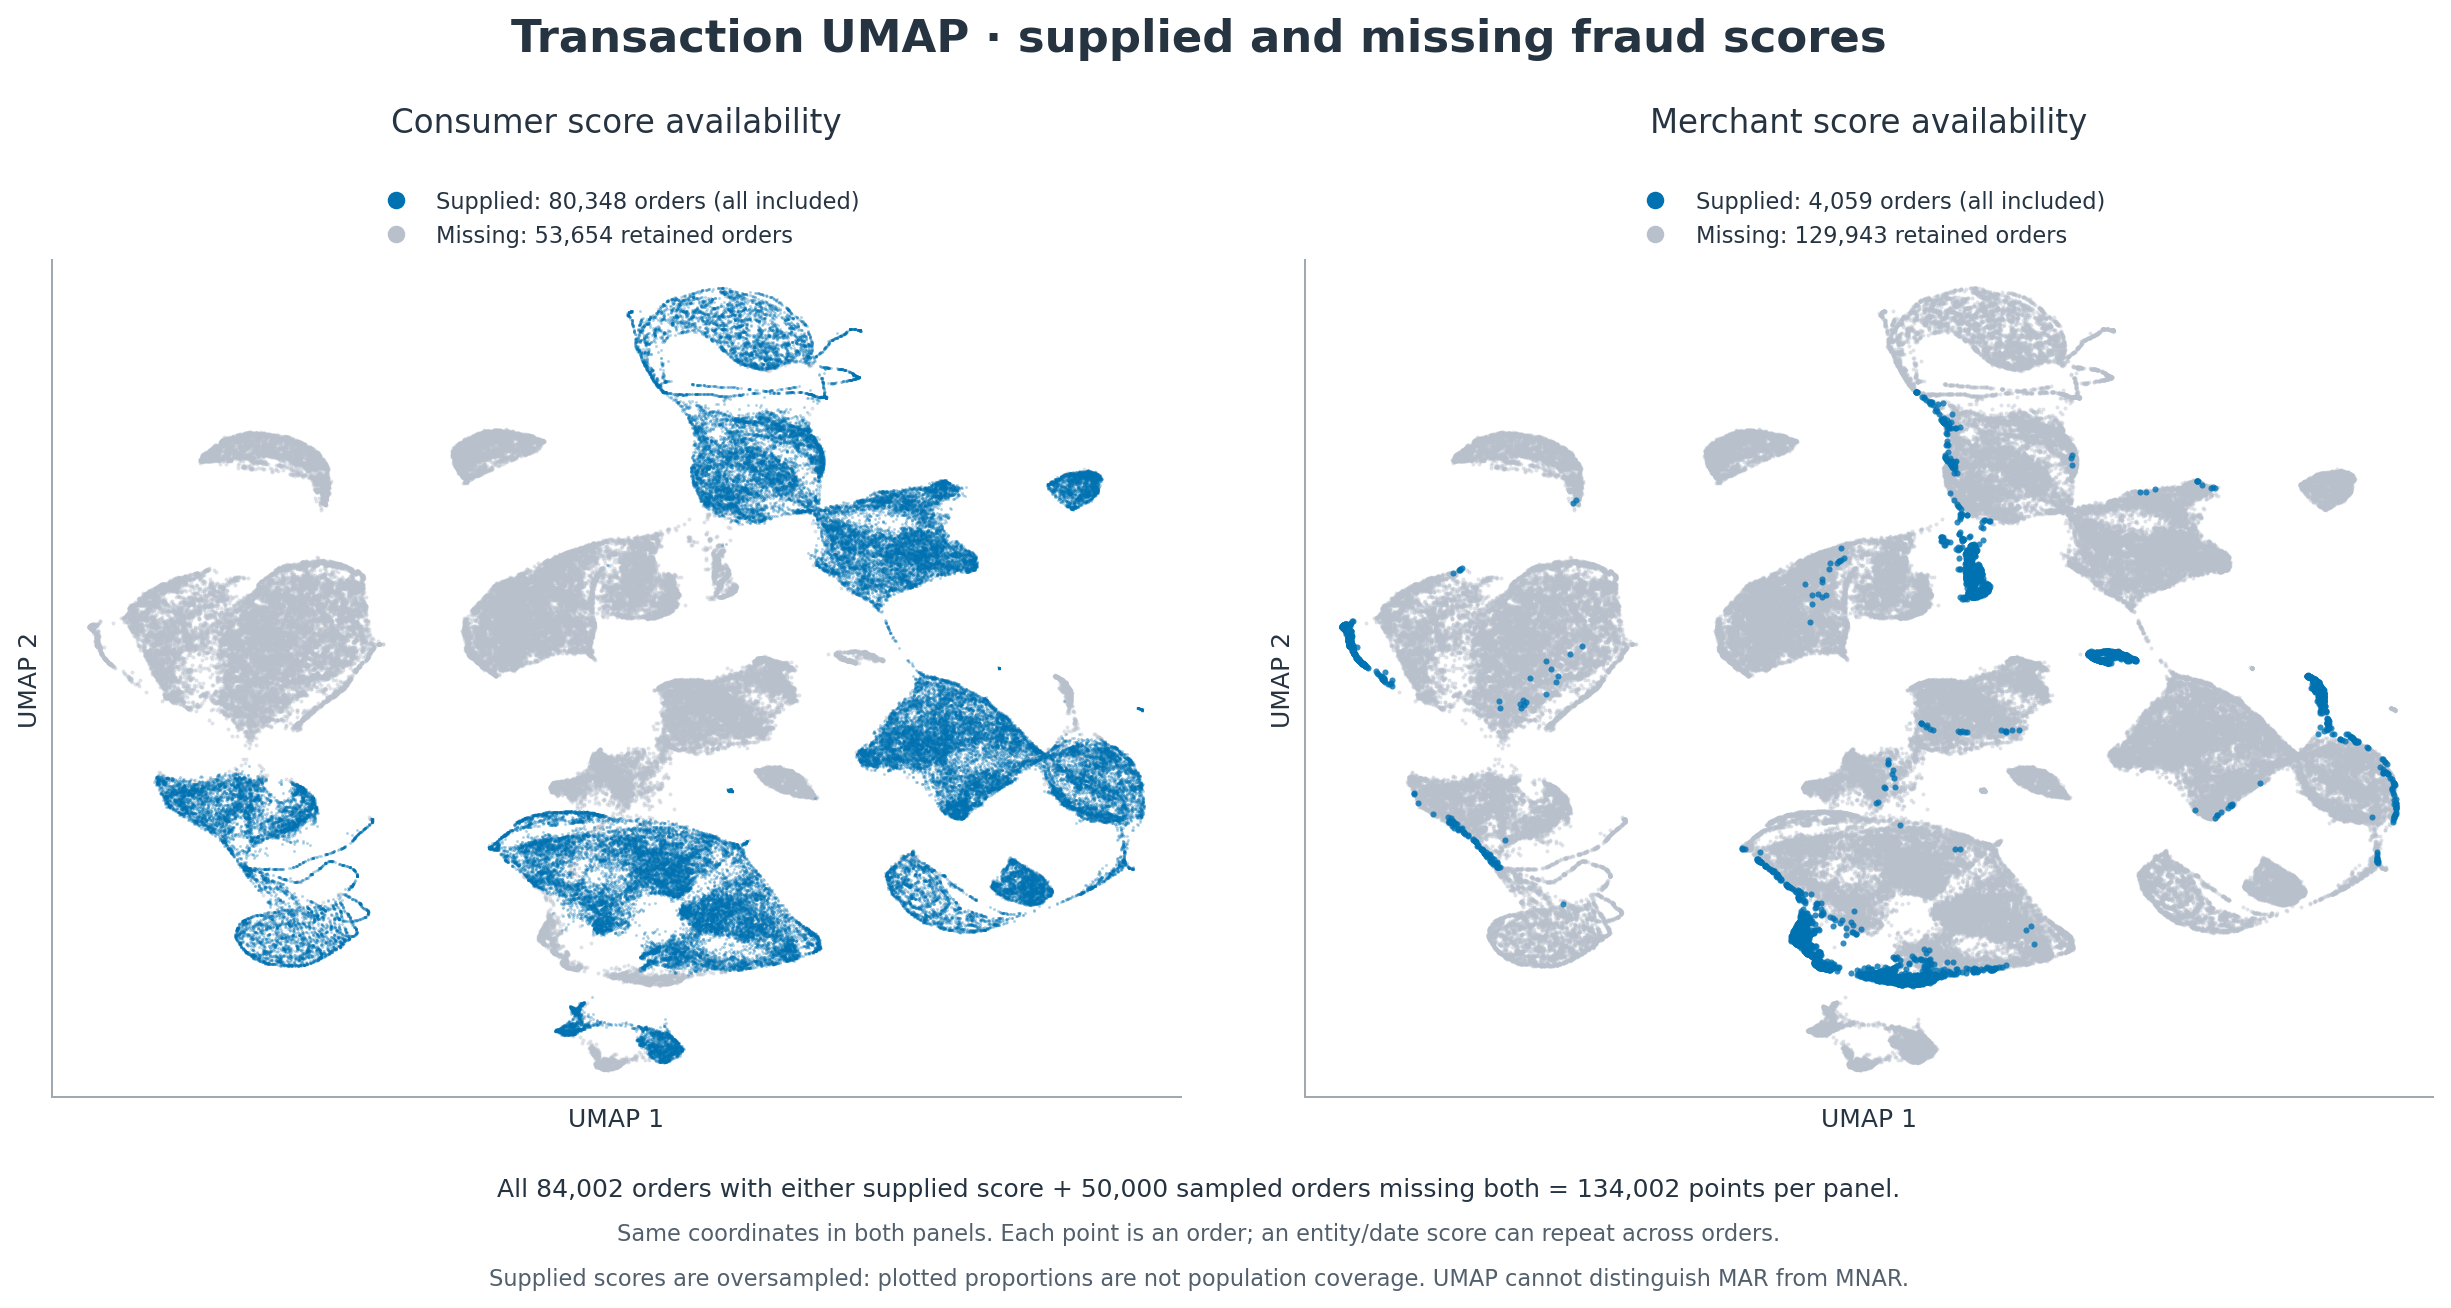

Population rows: 14,195,505
Retained rows: 134,002
Supplied entity/date scores retained: 34765 consumer; 114 merchant
Original score coverage by month (% of ALL transactions in that month):


,month,transaction_rows,consumer_supplied_rows,merchant_supplied_rows,consumer_supplied_pct,merchant_supplied_pct
0,2021-02,17107,40,0,0.2338,0.0000
1,2021-03,546333,1327,3,0.2429,0.0005
2,2021-04,560680,1437,1,0.2563,0.0002
3,2021-05,636666,1683,0,0.2643,0.0000
4,2021-06,627148,1685,0,0.2687,0.0000
5,2021-07,655279,1927,0,0.2941,0.0000
6,2021-08,688822,2946,2,0.4277,0.0003
7,2021-09,678524,9216,32,1.3582,0.0047
8,2021-10,729619,10320,30,1.4144,0.0041
9,2021-11,991226,19654,3862,1.9828,0.3896


Original score coverage by transaction amount and date window (% of ALL orders in each group):


,period,amount_bin,transaction_rows,consumer_supplied_rows,merchant_supplied_rows,amount_range,consumer_supplied_pct,merchant_supplied_pct
0,Outside consumer supplied-date window,1,2615127,0,0,Below $50,0.0000,0.0000
1,Outside consumer supplied-date window,2,1255300,0,0,$50–<100,0.0000,0.0000
2,Outside consumer supplied-date window,3,1263326,0,0,$100–<250,0.0000,0.0000
3,Outside consumer supplied-date window,4,522882,0,0,$250–<500,0.0000,0.0000
4,Outside consumer supplied-date window,5,256026,0,0,"$500–<1,000",0.0000,0.0000
5,Outside consumer supplied-date window,6,88595,0,0,"$1,000–<2,000",0.0000,0.0000
6,Outside consumer supplied-date window,7,35215,0,0,"$2,000–<5,000",0.0000,0.0000
7,Outside consumer supplied-date window,8,7662,0,0,"$5,000+",0.0000,0.0000
8,Within consumer supplied-date window,1,3525362,17857,606,Below $50,0.5065,0.0172
9,Within consumer supplied-date window,2,1691730,8910,669,$50–<100,0.5267,0.0395


Saved UMAP figures, coordinates, sampling metadata and population coverage tables in /Users/trollinmaster/Documents/Uni/Coding/VSCode/MAST30034/industry-project-group-19/tables/analysis/fraud_diagnostics


In [11]:
from IPython.display import Image, display

umap_root = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / "tables/analysis/merchant_score_features").is_dir()), None)
if umap_root is None:
    raise FileNotFoundError("Run from industry-project-group-19 or its code directory after the ETL.")
transaction_umap_data, transaction_umap_metadata = run_transaction_score_umap(umap_root)
transaction_umap_plot_paths = draw_transaction_score_umap(
    transaction_umap_data, transaction_umap_metadata,
    umap_root / "tables/analysis/fraud_diagnostics/figures")
transaction_umap_metadata["figure_paths"] = transaction_umap_plot_paths
Path(transaction_umap_metadata["paths"]["metadata"]).write_text(
    json.dumps(transaction_umap_metadata, indent=2, allow_nan=False) + "\n")
display(Image(filename=transaction_umap_plot_paths["png"], width=1200))
print("Population rows:", f"{transaction_umap_metadata['population_rows']:,}")
print("Retained rows:", f"{len(transaction_umap_data):,}")
print("Supplied entity/date scores retained:",
      transaction_umap_metadata["consumer_supplied_entity_dates"], "consumer;",
      transaction_umap_metadata["merchant_supplied_entity_dates"], "merchant")
print("Original score coverage by month (% of ALL transactions in that month):")
display(pd.read_csv(transaction_umap_metadata["paths"]["by_month"]).round(4))
print("Original score coverage by transaction amount and date window (% of ALL orders in each group):")
display(pd.read_csv(transaction_umap_metadata["paths"]["by_amount"]).round(4))
print("Saved UMAP figures, coordinates, sampling metadata and population coverage tables in",
      umap_root / "tables/analysis/fraud_diagnostics")


### What the plot and population coverage show

In this embedding, supplied scores concentrate in particular regions, especially for merchants, while other regions contain mostly missing scores. The population coverage tables below provide evidence in the original variables alongside that visual pattern.

The plot retains all **80,348 consumer-scored orders** and **4,059 merchant-scored orders** (405 orders have both), plus 50,000 orders with neither score. These represent **34,765 consumer/date labels** and **114 merchant/date labels**, not independent transaction fraud outcomes.

In all **14,195,505 transactions**, supplied-score coverage is only **0.5660% for consumers** and **0.0286% for merchants**. The much higher proportion of blue points in the UMAP is intentional oversampling.

| Observed pattern | Consumer score supplied | Merchant score supplied |
|---|---:|---:|
| Orders below $50, within the consumer label date window | 0.5065% | 0.0172% |
| Orders of $5,000 or more, within that same date window | 80.2130% | 1.8683% |
| Orders from March 2022 onward | 0% | 0% |

The consumer label date window is 28 February 2021–27 February 2022. The amount comparison uses all orders in that window, not the sampled embedding; it is an association and does not control for every other feature. There are **6,023,208 orders from March 2022 onward** with neither supplied score.

**Conclusion:** a simple MCAR assumption for the complete dataset is implausible because availability varies sharply with observed amount and calendar period. This does not establish MAR: dependence on the unobserved fraud score may remain after conditioning on observed features, so MNAR remains possible. The UMAP is an exploratory view of overlap and gaps; its apparent clusters, local colour density and spacing are not formal missingness tests. The fraud-score collection process and sensitivity analysis would be needed to assess the MAR/MNAR assumption further.
